# Previsão de atrasos de voos com Spark ML (US DOT Flight Delays 2015)

**Disciplina:** Processamento de Dados Massivos — IESB
**Tipo de problema (sorteado):** Classificação
**Ferramentas:** PySpark (DataFrame API + `pyspark.ml`), Python 3.12, Java 17

Este notebook cobre o pipeline completo: ingestão, limpeza, engenharia de atributos, modelagem com Spark ML, avaliação e persistência do modelo.

## 1. Contextualização

### 1.1 A base de dados
| Item | Descrição |
|---|---|
| **Fonte** | Kaggle — [US DOT Flight Delays](https://www.kaggle.com/datasets/usdot/flight-delays) (`usdot/flight-delays`) |
| **Origem dos dados** | U.S. Department of Transportation (DOT), Bureau of Transportation Statistics (BTS), *Airline On-Time Performance* |
| **Período** | Ano de 2015 (janeiro a dezembro) |
| **Arquivo principal** | `flights.csv`: cerca de 5,8 milhões de voos × 31 colunas (592 MB em texto) |
| **Arquivos auxiliares** | `airlines.csv` (códigos e nomes de companhias) e `airports.csv` (aeroportos, cidade, estado, latitude e longitude) |
| **Amostragem** | Nenhuma. Usamos todos os registros do arquivo publicado. Pela descrição do dataset, ele cobre voos domésticos das grandes companhias que reportam ao BTS, e não todos os voos dos EUA. |

A contagem exata de linhas e colunas é calculada com Spark na etapa 2.

### 1.2 Pergunta de negócio
> **Com as informações disponíveis antes da decolagem, um voo vai chegar ao destino com 15 minutos ou mais de atraso?**

Esse limiar de 15 minutos é a convenção usada pelo DOT/FAA para classificar um voo como atrasado. A variável-alvo será binária: `ATRASADO = 1` se `ARRIVAL_DELAY >= 15`, senão `0`.

**Por que isso importa:** companhias aéreas podem realocar equipe e aeronaves; aeroportos podem reorganizar portões; e passageiros podem decidir conexões com mais segurança. Prever o atraso com antecedência reduz custos operacionais e aumenta a satisfação do cliente.

### 1.3 Por que este é um problema de dados massivos
Os "Vs" de big data aplicados a este cenário:

- **Volume:** ~5,8 milhões de registros × 31 colunas em 592 MB de texto. Na memória, um DataFrame desse tamanho ocupa várias vezes o tamanho do arquivo, o que já pressiona ferramentas de máquina única como o pandas.
- **Velocidade:** os dados são gerados continuamente. São cerca de 16 mil voos por dia, e o BTS publica novos meses periodicamente. Um modelo real precisa ser reprocessado e reavaliado com frequência.
- **Variedade:** há atributos numéricos, horários codificados como `HHMM`, categóricas de alta cardinalidade (companhia, ~300 aeroportos de origem e destino) e tabelas auxiliares que exigem *joins*.
- **Veracidade:** muitos campos são nulos por natureza (voos cancelados não têm horário de chegada) e há códigos inconsistentes de aeroporto, o que exige limpeza em escala.

**Por que processamento distribuído:** o Spark divide os dados em partições processadas em paralelo, executa transformações de forma *preguiçosa* (lazy evaluation), otimizando o plano de execução antes de ler os dados, e oferece algoritmos de ML (`pyspark.ml`) que treinam sobre partições, como as árvores do Random Forest. O mesmo código roda de um notebook local até um cluster com centenas de nós.

**Honestidade sobre a escala:** o arquivo de 2015 cabe em um computador pessoal, e neste trabalho o Spark roda em modo local (`local[*]`, usando todos os núcleos da máquina). O argumento de dados massivos está em que o pipeline foi construído para escalar: a série histórica do BTS cobre décadas, e o mesmo notebook processaria vários anos de dados, algo que não caberia na memória de uma única máquina, simplesmente apontando para um cluster, sem reescrever o código.

### 1.4 Limitações já conhecidas
- Dados de um único ano (2015), então a sazonalidade e eventos pontuais podem não generalizar.
- Não há informação de clima nem de congestionamento do tráfego aéreo, que são causas importantes de atraso.
- Atrasos se propagam em cascata (a aeronave que chega atrasada atrasa o próximo voo), e o modelo não enxerga isso diretamente.

## 2. Ingestão

**Conceitos desta etapa**
- **`SparkSession`:** ponto de entrada do Spark. Aqui usamos `local[*]`, um único processo com um *worker* por núcleo.
- **Leitura preguiçosa (lazy):** `spark.read` só planeja a leitura; os dados só são lidos quando uma *ação* (`count`, `show`, `write`) é chamada.
- **Schema manual (`StructType`):** com `inferSchema`, o Spark precisaria de uma passada extra pelos 592 MB só para adivinhar os tipos, e poderia errar (por exemplo, colunas quase vazias). Declarar o schema é mais rápido e deixa os tipos sob nosso controle.
- **Parquet:** formato colunar e comprimido. Depois da primeira leitura do CSV, gravamos Parquet e passamos a ler dele, o que torna as próximas etapas bem mais leves.

In [1]:
import os
import sys
from pathlib import Path

# Os workers do PySpark chamam "python" pelo nome; no Windows isso pode cair no
# atalho da Microsoft Store. Apontamos explicitamente para o interpretador atual.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# No Windows, o Spark precisa do winutils.exe/hadoop.dll (Hadoop 3.3.x) para gravar
# arquivos (Parquet e model.save()). Definimos o HADOOP_HOME só dentro deste processo.
if sys.platform == "win32":
    hadoop_home = Path(os.environ.get("HADOOP_HOME", Path.home() / "hadoop"))
    if (hadoop_home / "bin" / "winutils.exe").exists():
        os.environ["HADOOP_HOME"] = str(hadoop_home)
        os.environ["PATH"] = str(hadoop_home / "bin") + os.pathsep + os.environ["PATH"]
    else:
        print(f"AVISO: winutils.exe não encontrado em {hadoop_home}\\bin. "
              "A gravação de arquivos pode falhar.")

In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")                          # todos os núcleos da máquina
    .appName("flight-delays-classificacao")
    .config("spark.driver.memory", "6g")         # em modo local, o driver executa tudo
    .config("spark.sql.shuffle.partitions", "24")  # padrão é 200; exagerado para uma máquina só
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| núcleos disponíveis:", spark.sparkContext.defaultParallelism)

Spark 3.5.9 | núcleos disponíveis: 12


### 2.1 Download da base a partir da fonte original
Os dados **não** ficam no GitHub: o `kagglehub` baixa a base do Kaggle (com cache local).
As credenciais devem estar nas variáveis de ambiente `KAGGLE_USERNAME` e `KAGGLE_KEY`, ou em `KAGGLE_API_TOKEN` (veja o `README.md`).

In [3]:
import kagglehub

caminho_kaggle = Path(kagglehub.dataset_download("usdot/flight-delays"))
print("Arquivos baixados em:", caminho_kaggle)
for arquivo in sorted(caminho_kaggle.glob("*.csv")):
    print(f"  {arquivo.name:15s} {arquivo.stat().st_size / 1e6:8.1f} MB")

c:\Users\colaborador\Documents\ML Spark\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Arquivos baixados em: C:\Users\colaborador\.cache\kagglehub\datasets\usdot\flight-delays\versions\1
  airlines.csv         0.0 MB
  airports.csv         0.0 MB
  flights.csv        592.4 MB


### 2.2 Schema manual do `flights.csv`
Todas as 31 colunas são declaradas com tipo explícito. Observações:
- Horários (`SCHEDULED_DEPARTURE`, `DEPARTURE_TIME` etc.) vêm como `HHMM` (por exemplo `0005`). Lemos como inteiro (`5` = 00:05) e converteremos para hora e minuto na engenharia de atributos.
- `ORIGIN_AIRPORT` e `DESTINATION_AIRPORT` ficam como texto, pois alguns registros podem trazer códigos numéricos em vez do código IATA de 3 letras. Isso será tratado na limpeza.
- As colunas de atraso por causa (`*_DELAY`) são quase sempre vazias; são nulas, e não zero.

In [4]:
from pyspark.sql.types import StructType, StructField, IntegerType, StringType

schema_voos = StructType([
    StructField("YEAR",                 IntegerType(), True),
    StructField("MONTH",                IntegerType(), True),
    StructField("DAY",                  IntegerType(), True),
    StructField("DAY_OF_WEEK",          IntegerType(), True),
    StructField("AIRLINE",              StringType(),  True),
    StructField("FLIGHT_NUMBER",        IntegerType(), True),
    StructField("TAIL_NUMBER",          StringType(),  True),
    StructField("ORIGIN_AIRPORT",       StringType(),  True),
    StructField("DESTINATION_AIRPORT",  StringType(),  True),
    StructField("SCHEDULED_DEPARTURE",  IntegerType(), True),
    StructField("DEPARTURE_TIME",       IntegerType(), True),
    StructField("DEPARTURE_DELAY",      IntegerType(), True),
    StructField("TAXI_OUT",             IntegerType(), True),
    StructField("WHEELS_OFF",           IntegerType(), True),
    StructField("SCHEDULED_TIME",       IntegerType(), True),
    StructField("ELAPSED_TIME",         IntegerType(), True),
    StructField("AIR_TIME",             IntegerType(), True),
    StructField("DISTANCE",             IntegerType(), True),
    StructField("WHEELS_ON",            IntegerType(), True),
    StructField("TAXI_IN",              IntegerType(), True),
    StructField("SCHEDULED_ARRIVAL",    IntegerType(), True),
    StructField("ARRIVAL_TIME",         IntegerType(), True),
    StructField("ARRIVAL_DELAY",        IntegerType(), True),
    StructField("DIVERTED",             IntegerType(), True),
    StructField("CANCELLED",            IntegerType(), True),
    StructField("CANCELLATION_REASON",  StringType(),  True),
    StructField("AIR_SYSTEM_DELAY",     IntegerType(), True),
    StructField("SECURITY_DELAY",       IntegerType(), True),
    StructField("AIRLINE_DELAY",        IntegerType(), True),
    StructField("LATE_AIRCRAFT_DELAY",  IntegerType(), True),
    StructField("WEATHER_DELAY",        IntegerType(), True),
])
print("Colunas declaradas:", len(schema_voos.fields))

Colunas declaradas: 31


### 2.3 Leitura do CSV e conversão para Parquet
Na primeira execução lemos o CSV com o schema manual e `mode="FAILFAST"`: se alguma célula não couber no tipo declarado, o Spark **interrompe com erro** em vez de transformá-la silenciosamente em nulo. Em seguida gravamos em Parquet (pasta `data/`, ignorada pelo git) e, daqui em diante, lemos sempre do Parquet.

In [5]:
DIR_DADOS = Path("data")
DIR_DADOS.mkdir(exist_ok=True)
caminho_parquet = DIR_DADOS / "flights.parquet"

if not caminho_parquet.exists():
    voos_csv = (
        spark.read
        .option("header", True)
        .option("mode", "FAILFAST")          # falha se algum valor violar o schema
        .schema(schema_voos)
        .csv(str(caminho_kaggle / "flights.csv"))
    )
    print("Partições de leitura do CSV:", voos_csv.rdd.getNumPartitions())
    voos_csv.write.mode("overwrite").parquet(str(caminho_parquet))
    print("Parquet gravado em", caminho_parquet)
else:
    print("Parquet já existe, reaproveitando:", caminho_parquet)

voos = spark.read.parquet(str(caminho_parquet))

Parquet já existe, reaproveitando: data\flights.parquet


### 2.4 Tabelas auxiliares
`airlines.csv` e `airports.csv` são minúsculos (dezenas e centenas de linhas), então aqui **usamos `inferSchema`**: o custo de uma passada extra é desprezível, e evita escrever um schema que não traz benefício.

In [6]:
companhias = (spark.read.option("header", True).option("inferSchema", True)
              .csv(str(caminho_kaggle / "airlines.csv")))
aeroportos = (spark.read.option("header", True).option("inferSchema", True)
              .csv(str(caminho_kaggle / "airports.csv")))
companhias.printSchema()
aeroportos.printSchema()

root
 |-- IATA_CODE: string (nullable = true)
 |-- AIRLINE: string (nullable = true)

root
 |-- IATA_CODE: string (nullable = true)
 |-- AIRPORT: string (nullable = true)
 |-- CITY: string (nullable = true)
 |-- STATE: string (nullable = true)
 |-- COUNTRY: string (nullable = true)
 |-- LATITUDE: double (nullable = true)
 |-- LONGITUDE: double (nullable = true)



### 2.5 Verificação da ingestão
Conferimos o tamanho real da base (e o requisito de pelo menos 200 mil registros) e olhamos uma amostra.

In [7]:
n_linhas = voos.count()          # primeira ação: aqui o Spark de fato lê os dados
n_colunas = len(voos.columns)
print(f"Registros: {n_linhas:,}".replace(",", "."))
print(f"Colunas:   {n_colunas}")
assert n_linhas >= 200_000, "A base precisa ter pelo menos 200 mil registros"
print("Partições do DataFrame:", voos.rdd.getNumPartitions())

# Comparação de armazenamento: CSV (texto) vs Parquet (colunar e comprimido)
tam_csv = (caminho_kaggle / "flights.csv").stat().st_size / 1e6
tam_parquet = sum(p.stat().st_size for p in caminho_parquet.rglob("*") if p.is_file()) / 1e6
print(f"CSV: {tam_csv:.0f} MB | Parquet: {tam_parquet:.0f} MB")

Registros: 5.819.079
Colunas:   31
Partições do DataFrame: 12
CSV: 592 MB | Parquet: 142 MB


In [8]:
voos.printSchema()
# Formato vertical: com 31 colunas, a tabela horizontal fica ilegível
voos.show(2, vertical=True, truncate=False)

root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: integer (nullable = true)
 |-- DEPARTURE_DELAY: integer (nullable = true)
 |-- TAXI_OUT: integer (nullable = true)
 |-- WHEELS_OFF: integer (nullable = true)
 |-- SCHEDULED_TIME: integer (nullable = true)
 |-- ELAPSED_TIME: integer (nullable = true)
 |-- AIR_TIME: integer (nullable = true)
 |-- DISTANCE: integer (nullable = true)
 |-- WHEELS_ON: integer (nullable = true)
 |-- TAXI_IN: integer (nullable = true)
 |-- SCHEDULED_ARRIVAL: integer (nullable = true)
 |-- ARRIVAL_TIME: integer (nullable = true)
 |-- ARRIVAL_DELAY: integer (null

## 3. Exploração e limpeza

Toda a exploração usa funções do Spark (`agg`, `groupBy`, `summary`, `join`, *window functions*). O pandas só entra no fim, para **plotar resultados já agregados** (poucas linhas), nunca para processar os 5,8 milhões de registros.

**Conceitos desta etapa**
- **Transformação × ação:** `filter`, `groupBy` e `join` só montam um plano; `count`, `show` e `toPandas` disparam a execução.
- **Estatísticas aproximadas:** `summary` e `approxQuantile` calculam quantis com um algoritmo aproximado, que evita ordenar todos os dados.
- **Nulos estruturais:** um nulo pode ser *ausência de informação* ou *"não se aplica"*. Tratá-los igual seria um erro.

### 3.1 Estatísticas descritivas

In [9]:
colunas_numericas = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "DISTANCE", "SCHEDULED_TIME", "TAXI_OUT", "AIR_TIME"]
(voos.select(colunas_numericas)
     .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
     .show())

+-------+------------------+-----------------+-----------------+-----------------+-----------------+------------------+
|summary|   DEPARTURE_DELAY|    ARRIVAL_DELAY|         DISTANCE|   SCHEDULED_TIME|         TAXI_OUT|          AIR_TIME|
+-------+------------------+-----------------+-----------------+-----------------+-----------------+------------------+
|  count|           5732926|          5714008|          5819079|          5819073|          5730032|           5714008|
|   mean| 9.370158275198389|4.407057357987598|822.3564947305235|141.6858915500802|16.07166225249702|113.51162809012519|
| stddev|37.080942496786925|39.27129709388634|607.7842873170473|75.21058230600212|8.895574065449809| 72.23082162028544|
|    min|               -82|              -87|               21|               18|                1|                 7|
|    25%|                -5|              -13|              373|               85|               11|                60|
|    50%|                -2|            

### 3.2 Valores nulos

In [10]:
from pyspark.sql import functions as F, Window

# Uma única passada pela base: soma de nulos de cada coluna
nulos = voos.agg(*[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in voos.columns]).first().asDict()
tabela_nulos = spark.createDataFrame(
    [(c, n, round(100 * n / n_linhas, 3)) for c, n in nulos.items() if n > 0],
    ["coluna", "nulos", "pct_nulos"],
).orderBy(F.desc("nulos"))
tabela_nulos.show(truncate=False)

+-------------------+-------+---------+
|coluna             |nulos  |pct_nulos|
+-------------------+-------+---------+
|CANCELLATION_REASON|5729195|98.455   |
|AIRLINE_DELAY      |4755640|81.725   |
|LATE_AIRCRAFT_DELAY|4755640|81.725   |
|AIR_SYSTEM_DELAY   |4755640|81.725   |
|WEATHER_DELAY      |4755640|81.725   |
|SECURITY_DELAY     |4755640|81.725   |
|ARRIVAL_DELAY      |105071 |1.806    |
|ELAPSED_TIME       |105071 |1.806    |
|AIR_TIME           |105071 |1.806    |
|ARRIVAL_TIME       |92513  |1.59     |
|TAXI_IN            |92513  |1.59     |
|WHEELS_ON          |92513  |1.59     |
|WHEELS_OFF         |89047  |1.53     |
|TAXI_OUT           |89047  |1.53     |
|DEPARTURE_TIME     |86153  |1.481    |
|DEPARTURE_DELAY    |86153  |1.481    |
|TAIL_NUMBER        |14721  |0.253    |
|SCHEDULED_TIME     |6      |0.0      |
+-------------------+-------+---------+



**Como ler os nulos:**
- `ARRIVAL_DELAY`, `ELAPSED_TIME` e `AIR_TIME` (1,8%) são nulos exatamente nos voos **cancelados ou desviados**: sem chegada, não há atraso para medir.
- `DEPARTURE_TIME` e `DEPARTURE_DELAY` (1,5%) são nulos nos voos **cancelados antes da partida** (por isso a contagem é um pouco menor que a de cancelados).
- As cinco colunas de atraso por causa (`AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`, `LATE_AIRCRAFT_DELAY`, `WEATHER_DELAY`, 81,7% nulas) só são preenchidas **quando o voo atrasou**. Esse nulo significa "não se aplica", não "dado perdido". Elas só existem *depois* do voo e entregam a resposta, então não poderão ser usadas como atributos (vazamento, etapa 4).
- `CANCELLATION_REASON` só existe para voos cancelados.

### 3.3 Duplicatas

In [11]:
dup_linhas = n_linhas - voos.dropDuplicates().count()

# Chave natural de um voo: mesma data, companhia, número, rota e horário programado
chave_natural = ["YEAR", "MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER",
                 "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE"]
dup_chave = n_linhas - voos.dropDuplicates(chave_natural).count()

print("Linhas totalmente duplicadas:      ", dup_linhas)
print("Duplicatas pela chave natural:     ", dup_chave)

Linhas totalmente duplicadas:       0
Duplicatas pela chave natural:      0


### 3.4 Valores inválidos e faixas
Verificamos se há valores impossíveis (distância não positiva, horário `HHMM` inexistente, mês/dia fora do calendário etc.) e olhamos os extremos dos atrasos.

In [12]:
hora_prevista = (F.col("SCHEDULED_DEPARTURE") / 100).cast("int")
minuto_previsto = F.col("SCHEDULED_DEPARTURE") % 100

invalidos = voos.agg(
    F.sum((F.col("DISTANCE") <= 0).cast("int")).alias("distancia_nao_positiva"),
    F.sum(((hora_prevista > 23) | (minuto_previsto > 59)).cast("int")).alias("horario_programado_invalido"),
    F.sum((~F.col("MONTH").between(1, 12)).cast("int")).alias("mes_fora_de_1_12"),
    F.sum((~F.col("DAY").between(1, 31)).cast("int")).alias("dia_fora_de_1_31"),
    F.sum((~F.col("DAY_OF_WEEK").between(1, 7)).cast("int")).alias("dia_semana_fora_de_1_7"),
    F.sum((F.col("TAXI_OUT") < 0).cast("int")).alias("taxi_out_negativo"),
    F.sum((F.col("SCHEDULED_TIME") <= 0).cast("int")).alias("tempo_programado_nao_positivo"),
).first().asDict()
print(invalidos)

extremos = voos.agg(
    F.min("ARRIVAL_DELAY").alias("atraso_chegada_min"), F.max("ARRIVAL_DELAY").alias("atraso_chegada_max"),
    F.min("DISTANCE").alias("distancia_min"), F.max("DISTANCE").alias("distancia_max"),
    F.countDistinct("AIRLINE").alias("companhias"),
    F.countDistinct("ORIGIN_AIRPORT").alias("origens_distintas"),
).first().asDict()
print(extremos)
print("Quantis de ARRIVAL_DELAY (1%, 5%, 50%, 95%, 99%):",
      voos.approxQuantile("ARRIVAL_DELAY", [0.01, 0.05, 0.5, 0.95, 0.99], 0.001))

{'distancia_nao_positiva': 0, 'horario_programado_invalido': 0, 'mes_fora_de_1_12': 0, 'dia_fora_de_1_31': 0, 'dia_semana_fora_de_1_7': 0, 'taxi_out_negativo': 0, 'tempo_programado_nao_positivo': 0}
{'atraso_chegada_min': -87, 'atraso_chegada_max': 1971, 'distancia_min': 21, 'distancia_max': 4983, 'companhias': 14, 'origens_distintas': 628}
Quantis de ARRIVAL_DELAY (1%, 5%, 50%, 95%, 99%): [-34.0, -25.0, -5.0, 66.0, 166.0]


**Resultado:** não há duplicatas nem valores fora de faixa. Os atrasos extremos (até ~33 horas) são reais, e não erros, e não serão removidos: o alvo é binário (`>= 15 min`), então um atraso de 3 ou de 30 horas conta igual.

**Mas há um problema:** o campo `origens_distintas` mostra cerca de **628** aeroportos de origem, quando `airports.csv` tem ~320. Investigamos na próxima seção.

### 3.5 Códigos de aeroporto inconsistentes (outubro)

In [13]:
def eh_numerico(coluna):
    return F.col(coluna).rlike("^[0-9]+$")

voos.filter(eh_numerico("ORIGIN_AIRPORT")).groupBy("MONTH").count().orderBy("MONTH").show()
exemplos = [r[0] for r in voos.filter(eh_numerico("ORIGIN_AIRPORT")).select("ORIGIN_AIRPORT").distinct().limit(6).collect()]
print("Exemplos de códigos numéricos:", exemplos)

+-----+------+
|MONTH| count|
+-----+------+
|   10|486165|
+-----+------+

Exemplos de códigos numéricos: ['12173', '14492', '11423', '11973', '11617', '10849']


**Diagnóstico:** em **outubro inteiro** (e só nele), `ORIGIN_AIRPORT` e `DESTINATION_AIRPORT` vêm com o *ID numérico do DOT* (por exemplo `12173`) em vez do código IATA de 3 letras (por exemplo `HNL`). Se ignorarmos isso, o modelo verá outubro como aeroportos totalmente novos, e numa divisão temporal o teste começaria com um mês inteiro de aeroportos desconhecidos.

**Não há tabela de conversão nos arquivos da base.** Solução: **recuperar o IATA a partir dos próprios dados**. Um voo regular (mesma `AIRLINE`, `FLIGHT_NUMBER`, `SCHEDULED_DEPARTURE` e `DISTANCE`) opera todos os dias na mesma rota; nos outros meses essa rota aparece com IATA. Para cada voo de outubro com um "gêmeo" nos demais meses, o par (ID → IATA) recebe um voto, e cada ID fica com o IATA mais votado. Mantemos apenas IDs com pureza >= 90% (fração de votos do vencedor).

In [14]:
chave_voo = ["AIRLINE", "FLIGHT_NUMBER", "SCHEDULED_DEPARTURE", "DISTANCE"]
com_id = eh_numerico("ORIGIN_AIRPORT") & eh_numerico("DESTINATION_AIRPORT")

# Referência: voos com IATA (todos os meses menos outubro). Rota mais frequente de cada chave.
rotas = (voos.filter(~eh_numerico("ORIGIN_AIRPORT") & ~eh_numerico("DESTINATION_AIRPORT"))
             .groupBy(*chave_voo, "ORIGIN_AIRPORT", "DESTINATION_AIRPORT").count())
mais_frequente = Window.partitionBy(*chave_voo).orderBy(F.desc("count"))
rotas = (rotas.withColumn("pos", F.row_number().over(mais_frequente)).filter("pos = 1")
              .select(*chave_voo, F.col("ORIGIN_AIRPORT").alias("origem_iata"),
                      F.col("DESTINATION_AIRPORT").alias("destino_iata")))

# Voos de outubro (com ID) que têm um "gêmeo" em outro mês
pares = voos.filter(com_id).join(rotas, chave_voo, "inner")

# Votos (ID -> IATA), juntando origem e destino
votos = (pares.select(F.col("ORIGIN_AIRPORT").alias("id"), F.col("origem_iata").alias("iata"))
         .unionByName(pares.select(F.col("DESTINATION_AIRPORT").alias("id"), F.col("destino_iata").alias("iata")))
         .groupBy("id", "iata").count())
total_votos = votos.groupBy("id").agg(F.sum("count").alias("total"))
vencedor = Window.partitionBy("id").orderBy(F.desc("count"))
mapa_ids = (votos.withColumn("pos", F.row_number().over(vencedor)).filter("pos = 1")
            .join(total_votos, "id")
            .withColumn("pureza", F.col("count") / F.col("total"))
            .filter("pureza >= 0.9")
            .select("id", "iata", "pureza", "total"))
mapa_ids = mapa_ids.cache()

ids_outubro = (voos.filter(com_id).select(F.col("ORIGIN_AIRPORT").alias("id"))
               .union(voos.filter(com_id).select(F.col("DESTINATION_AIRPORT").alias("id"))).distinct().count())
print(f"IDs numéricos distintos: {ids_outubro} | mapeados com pureza >= 90%: {mapa_ids.count()}")
mapa_ids.agg(F.avg("pureza").alias("pureza_media"), F.min("total").alias("votos_minimos")).show()
mapa_ids.orderBy("id").show(5)

IDs numéricos distintos: 307 | mapeados com pureza >= 90%: 301
+------------------+-------------+
|      pureza_media|votos_minimos|
+------------------+-------------+
|0.9995142376820346|            7|
+------------------+-------------+

+-----+----+------------------+-----+
|   id|iata|            pureza|total|
+-----+----+------------------+-----+
|10135| ABE|0.9937106918238994|  159|
|10136| ABI|               1.0|  402|
|10140| ABQ|               1.0| 3118|
|10141| ABR|               1.0|  121|
|10146| ABY|               1.0|  136|
+-----+----+------------------+-----+
only showing top 5 rows



In [15]:
# Aplica o mapa em origem e destino (join com a tabela pequena via broadcast)
mapa_o = F.broadcast(mapa_ids.select(F.col("id").alias("id_o"), F.col("iata").alias("iata_o")))
mapa_d = F.broadcast(mapa_ids.select(F.col("id").alias("id_d"), F.col("iata").alias("iata_d")))

voos_iata = (voos
    .join(mapa_o, F.col("ORIGIN_AIRPORT") == F.col("id_o"), "left")
    .join(mapa_d, F.col("DESTINATION_AIRPORT") == F.col("id_d"), "left")
    .withColumn("ORIGIN_AIRPORT", F.coalesce("iata_o", "ORIGIN_AIRPORT"))
    .withColumn("DESTINATION_AIRPORT", F.coalesce("iata_d", "DESTINATION_AIRPORT"))
    .drop("id_o", "iata_o", "id_d", "iata_d"))

# Voos de outubro cujo ID não pôde ser recuperado com segurança saem da base
sem_mapa = voos_iata.filter(eh_numerico("ORIGIN_AIRPORT") | eh_numerico("DESTINATION_AIRPORT")).count()
voos_iata = voos_iata.filter(~eh_numerico("ORIGIN_AIRPORT") & ~eh_numerico("DESTINATION_AIRPORT"))
print(f"Voos descartados por ID sem mapeamento seguro: {sem_mapa:,} ({100 * sem_mapa / n_linhas:.3f}%)")

# Conferência: ainda há aeroportos de origem fora de airports.csv?
fora = (voos_iata.select("ORIGIN_AIRPORT").distinct()
        .join(aeroportos, F.col("ORIGIN_AIRPORT") == aeroportos["IATA_CODE"], "left_anti"))
print("Origens distintas agora:", voos_iata.select("ORIGIN_AIRPORT").distinct().count(),
      "| fora de airports.csv:", fora.count())

Voos descartados por ID sem mapeamento seguro: 698 (0.012%)
Origens distintas agora: 322 | fora de airports.csv: 0


### 3.6 Voos cancelados e desviados
Estes voos **não têm `ARRIVAL_DELAY`**, então não existe rótulo para eles. Decisão: **removê-los do conjunto de modelagem**. Para saber o quanto isso poderia distorcer a taxa de atraso, fazemos uma **análise de sensibilidade**: calculamos os limites da taxa se todos os removidos fossem pontuais ou se todos fossem atrasados.

In [16]:
r = voos_iata.agg(
    F.count("*").alias("total"),
    F.sum("CANCELLED").alias("cancelados"),
    F.sum("DIVERTED").alias("desviados"),
    F.sum(F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0)).alias("atrasados"),
    F.sum(F.when(F.col("ARRIVAL_DELAY").isNotNull(), 1).otherwise(0)).alias("rotulados"),
).first()
removidos = r["total"] - r["rotulados"]
print(f"Total: {r['total']:,} | cancelados: {r['cancelados']:,} ({100 * r['cancelados'] / r['total']:.3f}%)"
      f" | desviados: {r['desviados']:,} ({100 * r['desviados'] / r['total']:.3f}%)")
print(f"Removidos (sem rótulo): {removidos:,} ({100 * removidos / r['total']:.2f}%)")
print(f"Taxa de atraso entre os rotulados:                  {100 * r['atrasados'] / r['rotulados']:.2f}%")
print(f"Limite inferior (todos os removidos pontuais):       {100 * r['atrasados'] / r['total']:.2f}%")
print(f"Limite superior (todos os removidos atrasados):      {100 * (r['atrasados'] + removidos) / r['total']:.2f}%")

Total: 5,818,381 | cancelados: 89,884 (1.545%) | desviados: 15,184 (0.261%)
Removidos (sem rótulo): 105,068 (1.81%)
Taxa de atraso entre os rotulados:                  18.61%
Limite inferior (todos os removidos pontuais):       18.28%
Limite superior (todos os removidos atrasados):      20.08%


**Por que removê-los é razoável:** (1) sem `ARRIVAL_DELAY` não há rótulo, e inventar um contaminaria as métricas; (2) mesmo no pior caso, a taxa de atraso muda em cerca de 1,5 ponto percentual; (3) tratar desvio como atraso seria uma suposição nossa, e não um dado do DOT.

**Ressalva (limitação):** esses voos **não são aleatórios**: o cancelamento é muito mais frequente no inverno (cerca de 4,8% dos voos em fevereiro contra ~0,5% em setembro) e é causado em boa parte por clima. O modelo, portanto, descreve voos **que operaram**, e não toda a programação.

### 3.7 Variável-alvo e base limpa
`ATRASADO = 1` se `ARRIVAL_DELAY >= 15` minutos (convenção do DOT/FAA), senão `0`. Gravamos a base limpa em Parquet para as próximas etapas.

In [17]:
caminho_limpos = DIR_DADOS / "voos_limpos.parquet"

(voos_iata
    .filter((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0))
    .withColumn("ATRASADO", (F.col("ARRIVAL_DELAY") >= 15).cast("int"))
    .write.mode("overwrite").parquet(str(caminho_limpos)))

voos_limpos = spark.read.parquet(str(caminho_limpos))
n_limpos = voos_limpos.count()
print(f"Base limpa: {n_limpos:,} registros".replace(",", "."))
print("Nulos em ARRIVAL_DELAY:", voos_limpos.filter(F.col("ARRIVAL_DELAY").isNull()).count())

balanceamento = voos_limpos.groupBy("ATRASADO").count().orderBy("ATRASADO")
balanceamento.withColumn("pct", F.round(100 * F.col("count") / n_limpos, 2)).show()
taxa_global = voos_limpos.agg(F.avg("ATRASADO")).first()[0]

Base limpa: 5.713.313 registros
Nulos em ARRIVAL_DELAY: 0
+--------+-------+-----+
|ATRASADO|  count|  pct|
+--------+-------+-----+
|       0|4649973|81.39|
|       1|1063340|18.61|
+--------+-------+-----+



**Desbalanceamento:** cerca de 1 em cada 5 voos atrasa. A classe positiva é minoria, então **acurácia sozinha engana** (prever "nunca atrasa" já acerta ~81%). Por isso usaremos AUC-ROC, AUC-PR, F1 e matriz de confusão, e trataremos o desbalanceamento na modelagem.

### 3.8 Análise exploratória visual
Cada gráfico parte de uma agregação feita **no Spark**; só o resultado (poucas linhas) vai para o pandas.

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

AZUL, LARANJA, TINTA, GRADE = "#2a78d6", "#eb6834", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
})
RAMPA_AZUL = LinearSegmentedColormap.from_list("rampa_azul", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])

In [19]:
voos_g = (voos_limpos
          .withColumn("HORA", (F.col("SCHEDULED_DEPARTURE") / 100).cast("int")))

def taxa_por(df, *colunas):
    # Agrega no Spark: nº de voos e taxa de atraso por grupo
    return (df.groupBy(*colunas)
              .agg(F.count("*").alias("voos"), F.avg("ATRASADO").alias("taxa"))
              .orderBy(*colunas).toPandas())

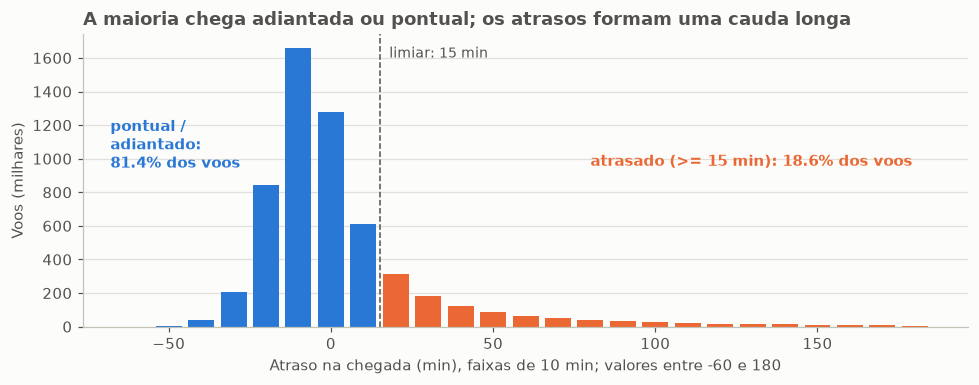

In [20]:
# 1) Distribuição do atraso na chegada (cortada em -60..180 min para legibilidade)
hist = (voos_limpos.filter(F.col("ARRIVAL_DELAY").between(-60, 179))
        .withColumn("faixa", F.floor((F.col("ARRIVAL_DELAY") - 15) / 10) * 10 + 15)   # faixas alinhadas ao limiar
        .groupBy("faixa").count().orderBy("faixa").toPandas())
cores = [LARANJA if f >= 15 else AZUL for f in hist["faixa"]]   # laranja: faixas que começam em 15 min ou mais

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(hist["faixa"] + 5, hist["count"] / 1e3, width=8, color=cores)
ax.axvline(15, color=TINTA, linestyle="--", linewidth=1)
topo_y = ax.get_ylim()[1]
ax.text(18, topo_y * 0.92, "limiar: 15 min", color=TINTA, fontsize=9)
ax.set_title("A maioria chega adiantada ou pontual; os atrasos formam uma cauda longa")
ax.set_xlabel("Atraso na chegada (min), faixas de 10 min; valores entre -60 e 180")
ax.set_ylabel("Voos (milhares)")
ax.text(-68, topo_y * 0.62, f"pontual /\nadiantado:\n{100 * (1 - taxa_global):.1f}% dos voos",
        color=AZUL, fontweight="bold", va="center")
ax.text(80, topo_y * 0.55, f"atrasado (>= 15 min): {100 * taxa_global:.1f}% dos voos",
        color=LARANJA, fontweight="bold")
plt.tight_layout(); plt.show()

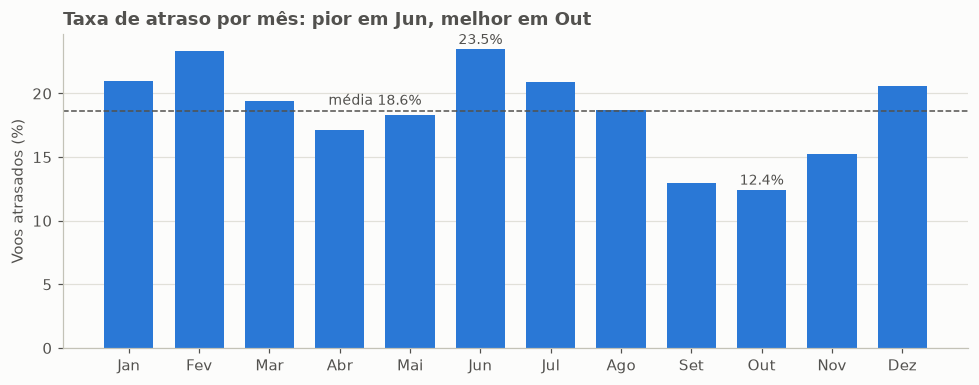

In [21]:
# 2) Taxa de atraso por mês
mes = taxa_por(voos_g, "MONTH")
nomes_mes = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(nomes_mes, 100 * mes["taxa"], color=AZUL, width=0.7)
ax.axhline(100 * taxa_global, color=TINTA, linestyle="--", linewidth=1)
ax.text(3.5, 100 * taxa_global + 0.5, f"média {100 * taxa_global:.1f}%", color=TINTA, ha="center", fontsize=9)
for i in (mes["taxa"].idxmax(), mes["taxa"].idxmin()):                  # rótulo só nos extremos
    ax.text(i, 100 * mes.loc[i, "taxa"] + 0.4, f"{100 * mes.loc[i, 'taxa']:.1f}%", ha="center", fontsize=9)
pior, melhor = mes["taxa"].idxmax(), mes["taxa"].idxmin()
ax.set_title(f"Taxa de atraso por mês: pior em {nomes_mes[pior]}, melhor em {nomes_mes[melhor]}")
ax.set_ylabel("Voos atrasados (%)")
plt.tight_layout(); plt.show()

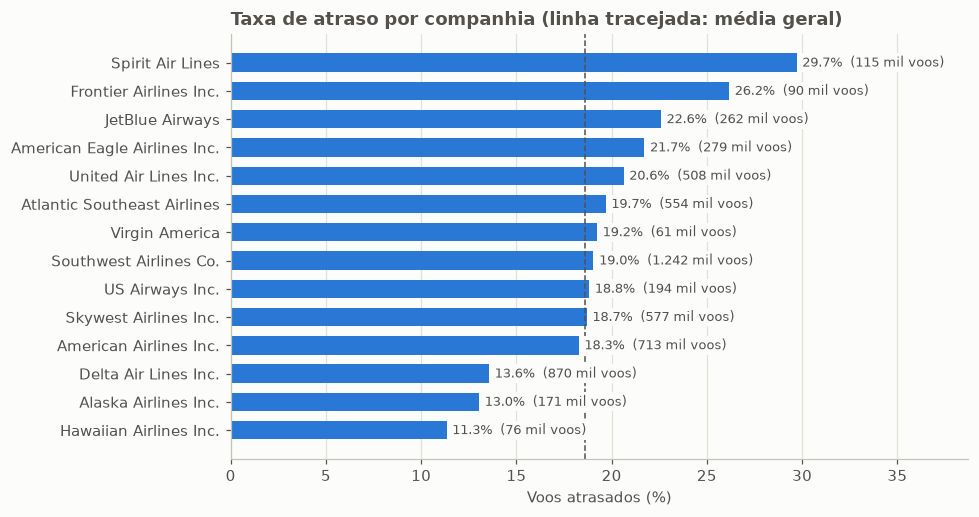

In [22]:
# 3) Taxa de atraso por companhia (com nome, via join com airlines.csv)
cia = (voos_limpos.groupBy("AIRLINE").agg(F.count("*").alias("voos"), F.avg("ATRASADO").alias("taxa"))
       .join(companhias.withColumnRenamed("AIRLINE", "nome"), F.col("AIRLINE") == F.col("IATA_CODE"))
       .toPandas().sort_values("taxa"))
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(cia["nome"], 100 * cia["taxa"], color=AZUL, height=0.65)
ax.axvline(100 * taxa_global, color=TINTA, linestyle="--", linewidth=1)
for y, (t, n) in enumerate(zip(cia["taxa"], cia["voos"])):
    mil_voos = f"{n / 1e3:,.0f}".replace(",", ".")
    ax.text(100 * t + 0.3, y, f"{100 * t:.1f}%  ({mil_voos} mil voos)", va="center", fontsize=8.5,
            bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1.5))
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlim(0, 100 * cia["taxa"].max() + 9)
ax.set_title("Taxa de atraso por companhia (linha tracejada: média geral)")
ax.set_xlabel("Voos atrasados (%)")
plt.tight_layout(); plt.show()

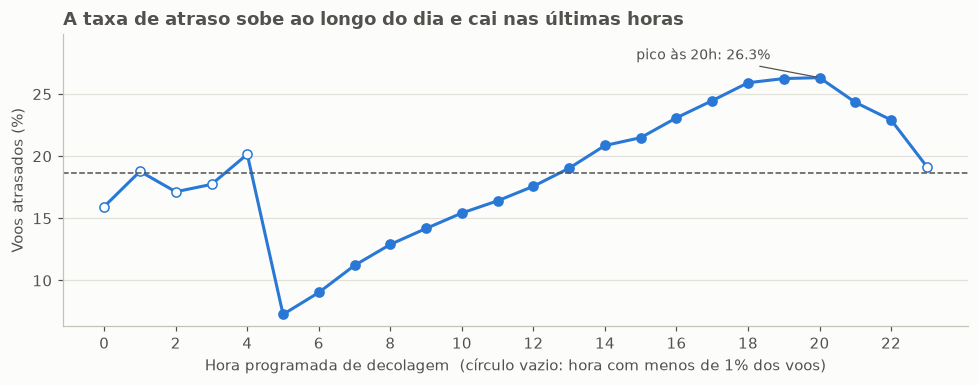

In [23]:
# 4) Taxa de atraso por hora programada de decolagem
hora = taxa_por(voos_g, "HORA")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(hora["HORA"], 100 * hora["taxa"], color=AZUL, linewidth=2)
poucos = hora["voos"] < 0.01 * n_limpos            # horas com menos de 1% dos voos: taxa menos estável
ax.plot(hora.loc[~poucos, "HORA"], 100 * hora.loc[~poucos, "taxa"], "o", color=AZUL, markersize=6)
ax.plot(hora.loc[poucos, "HORA"], 100 * hora.loc[poucos, "taxa"], "o", markerfacecolor="#fcfcfb",
        color=AZUL, markersize=6)
ax.axhline(100 * taxa_global, color=TINTA, linestyle="--", linewidth=1)
i = hora["taxa"].idxmax()
ax.set_ylim(top=100 * hora["taxa"].max() + 3.5)
ax.annotate(f"pico às {hora.loc[i, 'HORA']}h: {100 * hora.loc[i, 'taxa']:.1f}%",
            (hora.loc[i, "HORA"], 100 * hora.loc[i, "taxa"]), textcoords="offset points",
            xytext=(-120, 12), fontsize=9, arrowprops=dict(arrowstyle="-", color=TINTA, linewidth=0.8))
ax.set_xticks(range(0, 24, 2))
ax.set_title("A taxa de atraso sobe ao longo do dia e cai nas últimas horas")
ax.set_xlabel("Hora programada de decolagem  (círculo vazio: hora com menos de 1% dos voos)")
ax.set_ylabel("Voos atrasados (%)")
plt.tight_layout(); plt.show()

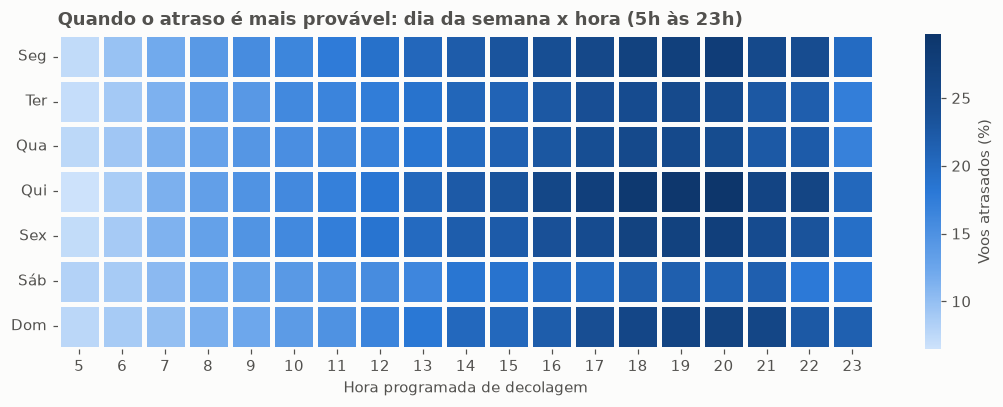

In [24]:
# 5) Mapa de calor: dia da semana x hora (células com poucos voos ficam em branco)
dh = taxa_por(voos_g.filter(F.col("HORA") >= 5), "DAY_OF_WEEK", "HORA")   # 0h-4h têm poucos voos
matriz = dh.pivot(index="DAY_OF_WEEK", columns="HORA", values="taxa") * 100
matriz.index = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]     # no BTS, 1 = segunda-feira
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(matriz, cmap=RAMPA_AZUL, ax=ax, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "Voos atrasados (%)"})
ax.grid(False)
ax.tick_params(axis="y", rotation=0)
ax.set_title("Quando o atraso é mais provável: dia da semana x hora (5h às 23h)")
ax.set_xlabel("Hora programada de decolagem"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

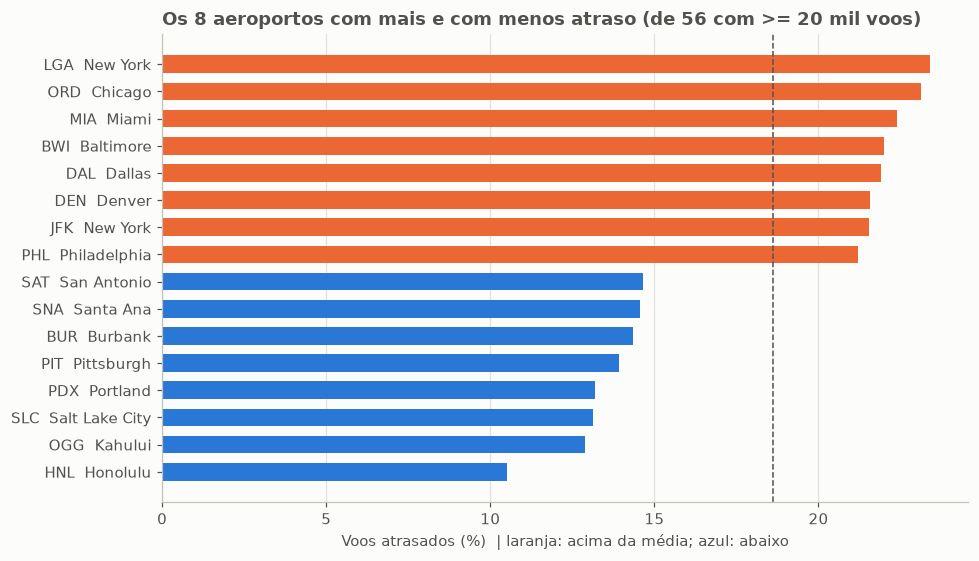

In [25]:
# 6) Aeroportos de origem com maior taxa de atraso (só aeroportos com >= 20 mil voos)
aero_taxa = (voos_limpos.groupBy("ORIGIN_AIRPORT").agg(F.count("*").alias("voos"), F.avg("ATRASADO").alias("taxa"))
             .filter("voos >= 20000")
             .join(aeroportos, F.col("ORIGIN_AIRPORT") == F.col("IATA_CODE"), "left")
             .toPandas().sort_values("taxa", ascending=False))
topo = pd.concat([aero_taxa.head(8), aero_taxa.tail(8)]).iloc[::-1]
cores = [LARANJA if t > taxa_global else AZUL for t in topo["taxa"]]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(topo["ORIGIN_AIRPORT"] + "  " + topo["CITY"].fillna(""), 100 * topo["taxa"], color=cores, height=0.65)
ax.axvline(100 * taxa_global, color=TINTA, linestyle="--", linewidth=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_title(f"Os 8 aeroportos com mais e com menos atraso (de {len(aero_taxa)} com >= 20 mil voos)")
ax.set_xlabel("Voos atrasados (%)  | laranja: acima da média; azul: abaixo")
plt.tight_layout(); plt.show()

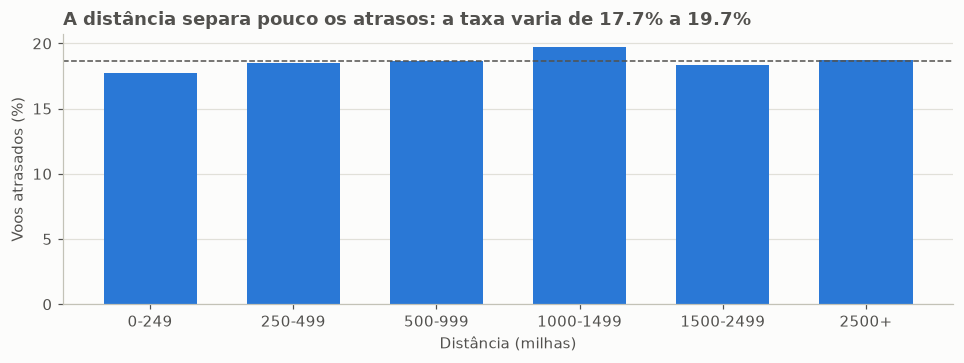

In [26]:
# 7) Taxa de atraso por faixa de distância
faixas = (voos_g.withColumn("faixa_dist", F.when(F.col("DISTANCE") < 250, "0-249")
                            .when(F.col("DISTANCE") < 500, "250-499")
                            .when(F.col("DISTANCE") < 1000, "500-999")
                            .when(F.col("DISTANCE") < 1500, "1000-1499")
                            .when(F.col("DISTANCE") < 2500, "1500-2499")
                            .otherwise("2500+")))
dist = taxa_por(faixas, "faixa_dist").set_index("faixa_dist").loc[["0-249", "250-499", "500-999", "1000-1499", "1500-2499", "2500+"]]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(dist.index, 100 * dist["taxa"], color=AZUL, width=0.65)
ax.axhline(100 * taxa_global, color=TINTA, linestyle="--", linewidth=1)
ax.set_title(f"A distância separa pouco os atrasos: a taxa varia de {100 * dist['taxa'].min():.1f}% a {100 * dist['taxa'].max():.1f}%")
ax.set_ylabel("Voos atrasados (%)"); ax.set_xlabel("Distância (milhas)")
plt.tight_layout(); plt.show()

### 3.9 O que a exploração nos diz

Lendo os gráficos acima (valores aproximados):
- **Alvo desbalanceado:** ~18,6% dos voos atrasam. Mês, hora e companhia mudam bastante essa taxa, então há sinal a explorar.
- **Sazonalidade forte:** a taxa varia de ~12% (outubro) a ~23% (junho e fevereiro). Isso pesa na divisão treino/teste: um teste em outubro–dezembro tem uma taxa de atraso diferente da do treino, e as métricas refletirão essa mudança de distribuição.
- **Hora do dia:** a taxa sobe de ~7% (5h) para ~26% (19h–20h), o que sugere **atrasos acumulados ao longo do dia** (uma aeronave atrasada de manhã atrasa os voos seguintes). Vamos criar atributos de hora, inclusive cíclicos.
- **Companhia e aeroporto:** variam de ~11% (Hawaiian) a ~30% (Spirit), e de ~10,5% (Honolulu) a ~23% (LaGuardia). Ambas são categóricas de alta relevância e entram como atributos (indexadas e codificadas).
- **Distância:** quase não separa (17,7% a 19,7%). Provavelmente tem pouco poder preditivo isolado.

### 3.10 Resumo da limpeza
| Passo | Registros | Observação |
|---|---|---|
| Base bruta (Parquet) | 5.819.079 | 31 colunas, 0 duplicatas, 0 valores fora de faixa |
| Após recuperar o IATA de outubro | 5.818.381 | 698 voos (0,012%) descartados por ID sem mapeamento seguro; 628 → 322 origens |
| Após remover cancelados e desviados | **5.713.313** | 105.068 voos sem rótulo; taxa de atraso sensível entre 18,3% e 20,1% |

Essa base limpa (`data/voos_limpos.parquet`, com a coluna `ATRASADO`) é a entrada da engenharia de atributos.

## 4. Engenharia de atributos e Pipeline

Esta etapa define **o que o modelo pode enxergar** (prevenção de vazamento), **como dividimos treino e teste** e **como os atributos são construídos**, tudo dentro de um `Pipeline` do Spark ML.

**Conceitos desta etapa**
- **Vazamento de dados (*data leakage*):** usar no treino uma informação que não existiria no momento real da previsão, ou que carrega a resposta disfarçada. As métricas ficam excelentes e o modelo é inútil.
- **`Pipeline` e `PipelineModel`:** o `Pipeline` encadeia transformadores e um estimador; `fit` aprende **só com os dados que recebe** (o treino) e devolve um `PipelineModel` que aplica exatamente as mesmas transformações a dados novos.
- **`SQLTransformer`:** permite criar atributos com SQL *dentro* do Pipeline, então o modelo salvo recebe colunas brutas e faz tudo sozinho.

### 4.1 Alvo e vazamento
Definimos **dois cenários**, para responder a duas perguntas diferentes:

- **Cenário A, antes da decolagem:** só informação de planejamento. É a pergunta de negócio original.
- **Cenário B, na saída do portão:** o cenário A mais `DEPARTURE_DELAY` (atraso na partida). Responde "o voo já saiu atrasado; vai chegar atrasado?".

In [27]:
from pathlib import Path
from pyspark.sql import functions as F

DIR_DADOS = Path("data")
voos_limpos = spark.read.parquet(str(DIR_DADOS / "voos_limpos.parquet"))

# Classificação de cada coluna quanto ao momento em que a informação existe
PLANEJAMENTO = ["YEAR", "MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE", "ORIGIN_AIRPORT",
                "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE", "SCHEDULED_TIME", "DISTANCE"]
SAIDA_PORTAO = ["DEPARTURE_DELAY"]                      # só existe no cenário B
PROIBIDAS = [                                           # só existem depois do voo (ou são o próprio alvo)
    "ARRIVAL_TIME", "ELAPSED_TIME", "AIR_TIME", "WHEELS_ON", "TAXI_IN", "ARRIVAL_DELAY",
    "DIVERTED", "CANCELLED", "CANCELLATION_REASON",
    "AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY",
]
NAO_USADAS = ["FLIGHT_NUMBER", "TAIL_NUMBER", "SCHEDULED_ARRIVAL",          # alta cardinalidade / redundantes
              "DEPARTURE_TIME", "TAXI_OUT", "WHEELS_OFF",                   # redundantes com DEPARTURE_DELAY
              "ATRASADO"]                                                   # o alvo

classificadas = set(PLANEJAMENTO + SAIDA_PORTAO + PROIBIDAS + NAO_USADAS)
assert classificadas == set(voos_limpos.columns), set(voos_limpos.columns) ^ classificadas
assert not (set(PLANEJAMENTO + SAIDA_PORTAO) & set(PROIBIDAS)), "coluna proibida entre as permitidas"
print("Todas as", len(voos_limpos.columns), "colunas foram classificadas; nenhuma coluna proibida entre as usadas.")

Todas as 32 colunas foram classificadas; nenhuma coluna proibida entre as usadas.


**Demonstração de vazamento.** As colunas de causa do atraso (`AIRLINE_DELAY`, `WEATHER_DELAY` etc.) só são preenchidas quando o voo atrasou. Treinamos uma regressão logística simples numa amostra de 5% usando-as: o resultado é bom *demais*.

In [28]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

causas = ["AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]
demo = voos_limpos.sample(fraction=0.05, seed=42).na.fill(0, subset=causas)   # nulo = "não atrasou" = 0
demo_treino, demo_teste = demo.filter("MONTH <= 9"), demo.filter("MONTH >= 10")

montador_demo = VectorAssembler(inputCols=causas + ["DISTANCE"], outputCol="features")
modelo_demo = LogisticRegression(labelCol="ATRASADO", maxIter=20).fit(montador_demo.transform(demo_treino))
auc_vazamento = (BinaryClassificationEvaluator(labelCol="ATRASADO", metricName="areaUnderROC")
                 .evaluate(modelo_demo.transform(montador_demo.transform(demo_teste))))
print(f"AUC com as colunas de causa (vazamento): {auc_vazamento:.4f}")

corr = voos_limpos.stat.corr("DEPARTURE_DELAY", "ARRIVAL_DELAY")
print(f"Correlação entre atraso na partida e atraso na chegada: {corr:.3f}")

AUC com as colunas de causa (vazamento): 1.0000
Correlação entre atraso na partida e atraso na chegada: 0.945


**Leitura:** um AUC próximo de 1,0 é um **sinal de alerta**, e não de sucesso: o modelo está lendo o gabarito. Já `DEPARTURE_DELAY` tem correlação alta com o atraso na chegada, mas é informação legítima *na hora da decolagem*; por isso ela entra apenas no cenário B, e esperamos que ele supere bastante o cenário A.

### 4.2 Divisão treino/teste: temporal
- **Treino:** janeiro a setembro. **Teste:** outubro a dezembro. Todo voo do treino acontece antes de qualquer voo do teste, como em produção.
- O corte cai na fronteira de um trimestre (nenhum dia fica dividido) e dá ~75% / 25%.
- Tudo que *aprende* com os dados (indexadores, padronização, lista dos principais aeroportos, pesos de classe, hiperparâmetros) usa **somente o treino**.
- `MONTH` **não** é atributo: o modelo nunca viu os meses 10 a 12 no treino.
- **Validação interna** (para escolher hiperparâmetros): treino em janeiro-julho, validação em agosto-setembro, também em ordem temporal. O teste fica intocado até a avaliação final.

In [29]:
treino = voos_limpos.filter(F.col("MONTH") <= 9)
teste = voos_limpos.filter(F.col("MONTH") >= 10)

for nome, df in (("treino (jan-set)", treino), ("teste (out-dez)", teste)):
    r = df.agg(F.count("*").alias("voos"), F.avg("ATRASADO").alias("taxa")).first()
    print(f"{nome:18s} {r['voos']:>9,} voos | taxa de atraso: {100 * r['taxa']:.2f}%".replace(",", "."))

# Pesos de classe, calculados SÓ no treino: peso = n / (2 * n_classe)
cont = {r["ATRASADO"]: r["count"] for r in treino.groupBy("ATRASADO").count().collect()}
n_treino = cont[0] + cont[1]
peso_pos, peso_neg = n_treino / (2 * cont[1]), n_treino / (2 * cont[0])
print(f"Pesos de classe: atrasado = {peso_pos:.3f} | pontual = {peso_neg:.3f}")

def com_peso(df):
    return df.withColumn("peso", F.when(F.col("ATRASADO") == 1, peso_pos).otherwise(peso_neg))

# Subconjuntos para o ajuste de hiperparâmetros (em ordem temporal dentro do treino)
tuning_treino = com_peso(voos_limpos.filter("MONTH <= 7").sample(fraction=0.10, seed=42))
tuning_valid = com_peso(voos_limpos.filter("MONTH BETWEEN 8 AND 9").sample(fraction=0.25, seed=42))
print("Amostra de tuning:", f"{tuning_treino.count():,}".replace(",", "."), "treino |",
      f"{tuning_valid.count():,}".replace(",", "."), "validação")

treino (jan-set)   4.299.046 voos | taxa de atraso: 19.45%
teste (out-dez)    1.414.267 voos | taxa de atraso: 16.07%
Pesos de classe: atrasado = 2.571 | pontual = 0.621
Amostra de tuning: 332.262 treino | 242.364 validação


### 4.3 Atributos
| Atributo | Tipo | Justificativa |
|---|---|---|
| `AIRLINE` | categórica (14) | companhias têm taxas de atraso bem diferentes (11% a 30%) |
| `ORIGEM_GRUPO`, `DESTINO_GRUPO` | categórica (top 50 + `OUTROS`) | aeroportos importam (10% a 23%); agrupar os raros evita ~640 colunas esparsas |
| `DAY_OF_WEEK` | categórica (7) | padrão semanal visível no mapa de calor |
| `HORA_SIN`, `HORA_COS` | numérica cíclica | 23h e 0h são vizinhas; seno e cosseno preservam essa proximidade |
| `FIM_DE_SEMANA` | binária | sábado e domingo se comportam diferente |
| `PERTO_FERIADO` | binária | feriados federais de 2015 e os dias vizinhos (±1 dia) |
| `DISTANCE`, `SCHEDULED_TIME` | numérica | duração e distância programadas (efeito pequeno isolado, mas pode interagir) |
| `DEPARTURE_DELAY` | numérica | **apenas no cenário B** |

A lista dos 50 aeroportos mais movimentados é calculada **somente no treino**.

In [30]:
from datetime import date, timedelta

def principais(coluna, k=50):
    # k aeroportos com mais voos NO TREINO
    return [r[0] for r in treino.groupBy(coluna).count().orderBy(F.desc("count")).limit(k).collect()]

top_origem, top_destino = principais("ORIGIN_AIRPORT"), principais("DESTINATION_AIRPORT")
cobertura = treino.filter(F.col("ORIGIN_AIRPORT").isin(top_origem)).count() / n_treino
print(f"Os 50 principais aeroportos de origem cobrem {100 * cobertura:.1f}% dos voos do treino")

# Feriados federais dos EUA em 2015 (o 4 de julho caiu num sábado: feriado observado em 3/7) e dias vizinhos
feriados = [date(2015, 1, 1), date(2015, 1, 19), date(2015, 2, 16), date(2015, 5, 25), date(2015, 7, 3),
            date(2015, 7, 4), date(2015, 9, 7), date(2015, 10, 12), date(2015, 11, 11), date(2015, 11, 26),
            date(2015, 12, 25)]
datas_feriado = sorted({str(f + timedelta(days=d)) for f in feriados for d in (-1, 0, 1)})

def lista_sql(valores):
    return ", ".join("'" + v + "'" for v in valores)

# Os atributos derivados são criados por um SQLTransformer DENTRO do Pipeline: o modelo salvo
# recebe as colunas brutas e faz tudo sozinho. Cada linha é calculada só a partir dela mesma.
sql_atributos = f'''
SELECT *,
  SIN(2 * PI() * HORA_DECIMAL / 24.0) AS HORA_SIN,
  COS(2 * PI() * HORA_DECIMAL / 24.0) AS HORA_COS,
  CASE WHEN DAY_OF_WEEK >= 6 THEN 1.0 ELSE 0.0 END AS FIM_DE_SEMANA,
  CASE WHEN CAST(make_date(YEAR, MONTH, DAY) AS STRING) IN ({lista_sql(datas_feriado)})
       THEN 1.0 ELSE 0.0 END AS PERTO_FERIADO,
  CASE WHEN ORIGIN_AIRPORT IN ({lista_sql(top_origem)}) THEN ORIGIN_AIRPORT ELSE 'OUTROS' END AS ORIGEM_GRUPO,
  CASE WHEN DESTINATION_AIRPORT IN ({lista_sql(top_destino)}) THEN DESTINATION_AIRPORT ELSE 'OUTROS' END AS DESTINO_GRUPO
FROM (
  SELECT *, CAST(SCHEDULED_DEPARTURE / 100 AS INT) + (SCHEDULED_DEPARTURE % 100) / 60.0 AS HORA_DECIMAL
  FROM __THIS__
)
'''

Os 50 principais aeroportos de origem cobrem 81.1% dos voos do treino


### 4.4 Pipeline de atributos
`SQLTransformer` → `StringIndexer` (categoria vira índice; `handleInvalid="keep"` guarda categorias novas num balde extra em vez de falhar) → `OneHotEncoder` → `VectorAssembler` (numéricas) → `StandardScaler` → `VectorAssembler` final (`features`).

A função abaixo monta as etapas de cada cenário. O estimador (modelo) é acrescentado depois.

In [31]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import SQLTransformer, StringIndexer, OneHotEncoder, StandardScaler

CATEGORICAS = ["AIRLINE", "ORIGEM_GRUPO", "DESTINO_GRUPO", "DAY_OF_WEEK"]

def etapas_features(cenario):
    numericas = ["DISTANCE", "SCHEDULED_TIME", "HORA_SIN", "HORA_COS"]
    if cenario == "B":
        numericas = numericas + ["DEPARTURE_DELAY"]          # única diferença entre os cenários
    indexadores = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in CATEGORICAS]
    codificador = OneHotEncoder(inputCols=[c + "_idx" for c in CATEGORICAS],
                                outputCols=[c + "_ohe" for c in CATEGORICAS], handleInvalid="keep")
    montar_numericas = VectorAssembler(inputCols=numericas, outputCol="num_bruto")
    padronizar = StandardScaler(inputCol="num_bruto", outputCol="num_padrao", withMean=True, withStd=True)
    montar_final = VectorAssembler(
        inputCols=[c + "_ohe" for c in CATEGORICAS] + ["num_padrao", "FIM_DE_SEMANA", "PERTO_FERIADO"],
        outputCol="features")
    return [SQLTransformer(statement=sql_atributos)] + indexadores + [codificador, montar_numericas,
                                                                      padronizar, montar_final]

# Conferência: o vetor final de cada cenário, ajustado só com a amostra de treino
for cen in ("A", "B"):
    amostra = Pipeline(stages=etapas_features(cen)).fit(tuning_treino).transform(tuning_treino.limit(5))
    print(f"Cenário {cen}: vetor de atributos com {amostra.first()['features'].size} dimensões")

Cenário A: vetor de atributos com 133 dimensões
Cenário B: vetor de atributos com 134 dimensões


## 5. Modelagem

**Conceitos desta etapa**
- **Regressão logística:** apesar do nome, é um *classificador linear*: combina os atributos linearmente (`w·x + b`), passa o resultado por uma sigmoide para obter uma **probabilidade** entre 0 e 1 e treina minimizando o *log loss*. Interpretável pelos coeficientes.
- **Random Forest:** conjunto de árvores de decisão treinadas em amostras diferentes; captura **não linearidades e interações** (por exemplo hora × aeroporto × companhia) sem que as criemos à mão.
- **Desbalanceamento:** usamos **pesos de classe** (`weightCol`): errar um voo atrasado (classe minoritária) custa ~4 vezes mais que errar um pontual.
- **Limiar de decisão:** a probabilidade vira classe ao comparar com um limiar. O padrão de 0,5 raramente é o ideal com classes desbalanceadas, então escolhemos o limiar que maximiza o F1 da classe "atrasado" **na validação**, nunca no teste.
- **Hiperparâmetros:** parâmetros que *não* são aprendidos (por exemplo, profundidade das árvores). Testamos uma grade pequena numa amostra e escolhemos pela **AUC-PR** na validação temporal (agosto-setembro), que é a métrica mais informativa com classes desbalanceadas.

### 5.1 Linha de base
Referência ingênua: prever sempre "não atrasa".

In [32]:
import time
import pandas as pd
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder
from pyspark.ml.functions import vector_to_array

aval_roc = BinaryClassificationEvaluator(labelCol="ATRASADO", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
aval_pr = BinaryClassificationEvaluator(labelCol="ATRASADO", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

taxa_teste = teste.agg(F.avg("ATRASADO")).first()[0]
print(f"Linha de base (sempre 'não atrasa') no teste: acurácia = {100 * (1 - taxa_teste):.2f}% | "
      f"AUC-ROC = 0,50 | AUC-PR = {taxa_teste:.4f} (= taxa de atraso) | F1 da classe atrasado = 0")

Linha de base (sempre 'não atrasa') no teste: acurácia = 83.93% | AUC-ROC = 0,50 | AUC-PR = 0.1607 (= taxa de atraso) | F1 da classe atrasado = 0


Repare que a linha de base acerta ~84% **sem prever nenhum atraso**, e por isso a acurácia sozinha não serve aqui.

### 5.2 Funções auxiliares: probabilidade, limiar e matriz de confusão
Tudo é calculado no Spark, a partir da probabilidade da classe "atrasado" (`p1`).

In [33]:
def com_prob(df_predito):
    # extrai a probabilidade da classe 1 (atrasado) do vetor 'probability'
    return df_predito.withColumn("p1", vector_to_array("probability")[1])

def exprs_confusao(limiar, sufixo=""):
    prev, real = F.col("p1") >= limiar, F.col("ATRASADO") == 1
    return [F.sum((prev & real).cast("int")).alias("tp" + sufixo),
            F.sum((prev & ~real).cast("int")).alias("fp" + sufixo),
            F.sum((~prev & real).cast("int")).alias("fn" + sufixo),
            F.sum((~prev & ~real).cast("int")).alias("tn" + sufixo)]

def metricas_de(tp, fp, fn, tn):
    precisao = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precisao * recall / (precisao + recall) if precisao + recall else 0.0
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn, "precisao": precisao, "recall": recall, "f1": f1}

def avaliar_no_limiar(df_prob, limiar):
    r = df_prob.agg(*exprs_confusao(limiar)).first()
    return metricas_de(r["tp"], r["fp"], r["fn"], r["tn"])

LIMIARES = [round(0.05 * i, 2) for i in range(1, 20)]          # 0,05 ... 0,95

def melhor_limiar(df_prob):
    # uma única passada calcula a matriz de confusão de todos os limiares; escolhe o de maior F1
    exprs = []
    for t in LIMIARES:
        exprs += exprs_confusao(t, "_" + str(int(round(100 * t))))
    r = df_prob.agg(*exprs).first()
    f1s = {t: metricas_de(*[r[k + "_" + str(int(round(100 * t)))] for k in ("tp", "fp", "fn", "tn")])["f1"]
           for t in LIMIARES}
    return max(f1s, key=f1s.get)

### 5.3 Ajuste de hiperparâmetros (amostra, validação temporal)
Para cada cenário e modelo: ajustamos o Pipeline de atributos na amostra de treino (jan-jul), treinamos cada combinação da grade e avaliamos em ago-set. O melhor conjunto também define o **limiar de decisão** (F1 máximo na validação).

In [34]:
lr = LogisticRegression(labelCol="ATRASADO", featuresCol="features", weightCol="peso", maxIter=50)
grade_lr = (ParamGridBuilder()
            .addGrid(lr.regParam, [0.001, 0.01, 0.1])
            .addGrid(lr.elasticNetParam, [0.0, 0.5])
            .build())

rf = RandomForestClassifier(labelCol="ATRASADO", featuresCol="features", weightCol="peso", seed=42)
grade_rf = (ParamGridBuilder()
            .addGrid(rf.numTrees, [30, 60])
            .addGrid(rf.maxDepth, [8, 12])
            .build())

def nomes_params(pm):
    return {p.name: v for p, v in pm.items()}

def ajustar_hiperparametros(cenario, estimador, grade):
    t0 = time.time()
    feat = Pipeline(stages=etapas_features(cenario)).fit(tuning_treino)
    tr = feat.transform(tuning_treino).select("ATRASADO", "peso", "features").cache()
    va = feat.transform(tuning_valid).select("ATRASADO", "peso", "features").cache()
    tr.count(); va.count()

    linhas = []
    for pm in grade:
        pred = estimador.copy(pm).fit(tr).transform(va)
        linhas.append({**nomes_params(pm), "AUC_PR_valid": aval_pr.evaluate(pred), "AUC_ROC_valid": aval_roc.evaluate(pred)})
    tabela = pd.DataFrame(linhas)
    i_melhor = int(tabela["AUC_PR_valid"].idxmax())
    pm_melhor = grade[i_melhor]

    pred_melhor = com_prob(estimador.copy(pm_melhor).fit(tr).transform(va))
    limiar = melhor_limiar(pred_melhor)
    tr.unpersist(); va.unpersist()
    print(f"  cenário {cenario}: melhor = {nomes_params(pm_melhor)} | limiar (F1 na validação) = {limiar:.2f} "
          f"| {time.time() - t0:.0f}s")
    return {"pm": pm_melhor, "limiar": limiar, "tabela": tabela}

tuning = {}
for cenario in ("A", "B"):
    for nome, (est, grade) in {"Regressão logística": (lr, grade_lr), "Random Forest": (rf, grade_rf)}.items():
        print(nome)
        tuning[(cenario, nome)] = ajustar_hiperparametros(cenario, est, grade)

Regressão logística
  cenário A: melhor = {'regParam': 0.001, 'elasticNetParam': 0.0} | limiar (F1 na validação) = 0.50 | 57s
Random Forest
  cenário A: melhor = {'numTrees': 60, 'maxDepth': 12} | limiar (F1 na validação) = 0.50 | 140s
Regressão logística
  cenário B: melhor = {'regParam': 0.001, 'elasticNetParam': 0.5} | limiar (F1 na validação) = 0.70 | 51s
Random Forest
  cenário B: melhor = {'numTrees': 60, 'maxDepth': 12} | limiar (F1 na validação) = 0.70 | 11154s


In [35]:
for (cenario, nome), res in tuning.items():
    print(f"--- Cenário {cenario} | {nome}")
    print(res["tabela"].round(4).to_string(index=False))

--- Cenário A | Regressão logística
 regParam  elasticNetParam  AUC_PR_valid  AUC_ROC_valid
    0.001              0.0        0.2271         0.6299
    0.001              0.5        0.2268         0.6299
    0.010              0.0        0.2270         0.6297
    0.010              0.5        0.2250         0.6286
    0.100              0.0        0.2269         0.6290
    0.100              0.5        0.2106         0.6160
--- Cenário A | Random Forest
 numTrees  maxDepth  AUC_PR_valid  AUC_ROC_valid
       30         8        0.2300         0.6310
       30        12        0.2355         0.6374
       60         8        0.2308         0.6315
       60        12        0.2363         0.6373
--- Cenário B | Regressão logística
 regParam  elasticNetParam  AUC_PR_valid  AUC_ROC_valid
    0.001              0.0        0.8615         0.9320
    0.001              0.5        0.8618         0.9320
    0.010              0.0        0.8546         0.9281
    0.010              0.5        0.8

### 5.4 Ajuste final
Com os melhores hiperparâmetros, o **Pipeline completo** (atributos + modelo) é ajustado no **treino (jan-set)**. A regressão logística usa todo o treino; o Random Forest usa **50% do treino** (amostra com `seed` fixa), porque o Spark guarda os dados discretizados em memória e 4,3 milhões de linhas × 133 atributos não cabem com folga em 6 GB de memória do *driver*. Essa é uma limitação do ambiente local, e não do método: em cluster, usaríamos o treino inteiro.

In [36]:
FRACAO_TREINO = {"Regressão logística": 1.0, "Random Forest": 0.5}
estimadores = {"Regressão logística": lr, "Random Forest": rf}

modelos_finais = {}
for (cenario, nome), res in tuning.items():
    t0 = time.time()
    base = treino if FRACAO_TREINO[nome] >= 1 else treino.sample(fraction=FRACAO_TREINO[nome], seed=42)
    pipeline = Pipeline(stages=etapas_features(cenario) + [estimadores[nome].copy(res["pm"])])
    modelos_finais[(cenario, nome)] = pipeline.fit(com_peso(base))
    print(f"Cenário {cenario} | {nome}: treinado em {time.time() - t0:.0f}s")

Cenário A | Regressão logística: treinado em 45s
Cenário A | Random Forest: treinado em 203s
Cenário B | Regressão logística: treinado em 47s
Cenário B | Random Forest: treinado em 204s


## 6. Avaliação e interpretação

Todas as métricas abaixo vêm do **conjunto de teste (outubro-dezembro)**, que não foi usado em nenhuma decisão: nem atributos, nem hiperparâmetros, nem limiar.

**Métricas**
- **AUC-ROC:** probabilidade de o modelo dar nota maior a um voo atrasado do que a um pontual (0,5 = acaso, 1,0 = perfeito). Pouco sensível à mudança de taxa de atraso entre treino e teste.
- **AUC-PR:** área sob a curva precisão × recall. Com classes desbalanceadas é mais exigente; o acaso vale a própria taxa de atraso (~16%).
- **Precisão, recall e F1 da classe "atrasado":** no limiar escolhido na validação. Precisão = dos voos que o modelo alertou, quantos realmente atrasaram. Recall = dos que atrasaram, quantos o modelo pegou.
- **F1 ponderado:** média do F1 das duas classes, ponderada pelo tamanho, também reportada porque é a que o `MulticlassClassificationEvaluator` do Spark calcula por padrão.

### 6.1 Métricas no teste

In [37]:
mc_f1_pond = MulticlassClassificationEvaluator(labelCol="ATRASADO", predictionCol="pred_limiar", metricName="f1")

predicoes, linhas = {}, []
for (cenario, nome), modelo in modelos_finais.items():
    pred = com_prob(modelo.transform(teste)).select("ATRASADO", "rawPrediction", "p1").cache()
    pred.count()
    predicoes[(cenario, nome)] = pred

    limiar = tuning[(cenario, nome)]["limiar"]
    m = avaliar_no_limiar(pred, limiar)
    f1_pond = mc_f1_pond.evaluate(pred.withColumn("pred_limiar", (F.col("p1") >= limiar).cast("double")))
    linhas.append({
        "Cenário": cenario, "Modelo": nome, "AUC-ROC": aval_roc.evaluate(pred), "AUC-PR": aval_pr.evaluate(pred),
        "Limiar": limiar, "Precisão": m["precisao"], "Recall": m["recall"],
        "F1 (atrasado)": m["f1"], "F1 ponderado": f1_pond, "Acurácia": (m["tp"] + m["tn"]) / (m["tp"] + m["fp"] + m["fn"] + m["tn"]),
    })

metricas = pd.DataFrame(linhas)
baseline = pd.DataFrame([{"Cenário": "-", "Modelo": "Linha de base (sempre pontual)", "AUC-ROC": 0.5, "AUC-PR": taxa_teste,
                          "Limiar": float("nan"), "Precisão": 0.0, "Recall": 0.0, "F1 (atrasado)": 0.0,
                          "F1 ponderado": float("nan"), "Acurácia": 1 - taxa_teste}])
tabela_metricas = pd.concat([baseline, metricas], ignore_index=True)
print(tabela_metricas.round(4).to_string(index=False))

Cenário                         Modelo  AUC-ROC  AUC-PR  Limiar  Precisão  Recall  F1 (atrasado)  F1 ponderado  Acurácia
      - Linha de base (sempre pontual)   0.5000  0.1607     NaN    0.0000  0.0000         0.0000           NaN    0.8393
      A            Regressão logística   0.6064  0.2163     0.5    0.2087  0.5898         0.3083        0.6310    0.5745
      A                  Random Forest   0.6117  0.2209     0.5    0.2071  0.6068         0.3088        0.6211    0.5634
      B            Regressão logística   0.9276  0.8517     0.7    0.8416  0.7295         0.7815        0.9325    0.9344
      B                  Random Forest   0.9088  0.7972     0.7    0.7658  0.7720         0.7689        0.9255    0.9254


**Leitura da tabela (teste, out-dez):**
- **Acurácia engana:** a linha de base, que nunca prevê atraso, tem 83,9% de acurácia, mais que qualquer modelo do cenário A (~57%). Por isso a comparação usa AUC, AUC-PR e F1 da classe "atrasado".
- **Cenário A (antes da decolagem):** AUC-ROC de 0,61 (acaso = 0,50) e AUC-PR de ~0,22 contra 0,16 do acaso. Há sinal, mas **modesto**: no limiar escolhido, de cada 5 alertas só ~1 é atraso real (precisão ~21%, contra 16% de atrasos na base), embora o modelo pegue ~60% dos atrasos (recall).
- **Cenário B (na saída do portão):** AUC-ROC de **0,93** e AUC-PR de **0,85**; precisão de 84% e recall de 73% (F1 = 0,78). O salto vem quase todo de `DEPARTURE_DELAY`.
- **Regressão logística x Random Forest:** no cenário A empatam (diferença de ~0,005 de AUC). No cenário B a **regressão logística vence** (AUC 0,928 contra 0,909), contrariando a hipótese inicial: a relação entre atraso na saída e atraso na chegada é quase linear, e o Random Forest ficou limitado pela grade (melhor configuração na borda, profundidade 12) e por treinar em 50% dos dados.
- **Validação x teste:** os AUC do teste ficam um pouco abaixo dos da validação (por exemplo, cenário A: 0,637 para 0,612 no Random Forest), coerente com a mudança de distribuição entre os períodos (taxa de atraso de 19,5% no treino para 16,1% no teste) e com o fato de os hiperparâmetros terem sido escolhidos na validação.

### 6.2 Curvas ROC e Precisão × Recall
Calculadas no Spark varrendo limiares de 0 a 1 (uma passada por modelo). Cor = modelo; traço = cenário.

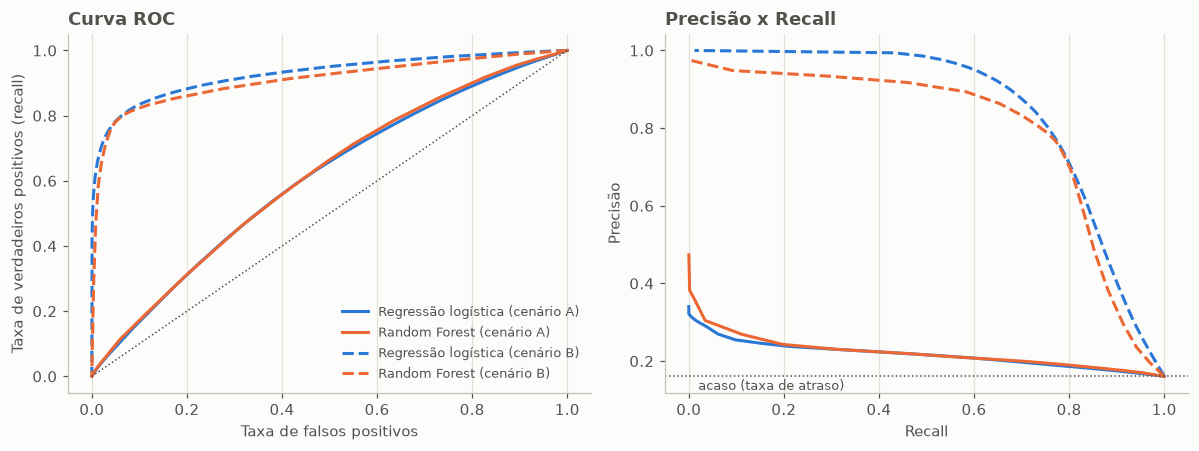

In [38]:
LIMIARES_CURVA = [i / 50 for i in range(0, 51)]

def curva(df_prob):
    exprs = []
    for k, t in enumerate(LIMIARES_CURVA):
        exprs += exprs_confusao(t, "_" + str(k))
    r = df_prob.agg(*exprs).first()
    pontos = []
    for k in range(len(LIMIARES_CURVA)):
        tp, fp, fn, tn = (r[x + "_" + str(k)] for x in ("tp", "fp", "fn", "tn"))
        pontos.append({"fpr": fp / (fp + tn), "tpr": tp / (tp + fn),
                       "precisao": tp / (tp + fp) if tp + fp else float("nan")})
    return pd.DataFrame(pontos)

curvas = {chave: curva(df) for chave, df in predicoes.items()}

COR = {"Regressão logística": AZUL, "Random Forest": LARANJA}
TRACO = {"A": "-", "B": "--"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for (cenario, nome), c in curvas.items():
    rotulo = f"{nome} (cenário {cenario})"
    ax1.plot(c["fpr"], c["tpr"], color=COR[nome], linestyle=TRACO[cenario], linewidth=2, label=rotulo)
    ax2.plot(c["tpr"], c["precisao"], color=COR[nome], linestyle=TRACO[cenario], linewidth=2, label=rotulo)
ax1.plot([0, 1], [0, 1], color=TINTA, linewidth=1, linestyle=":")
ax2.axhline(taxa_teste, color=TINTA, linewidth=1, linestyle=":")
ax1.set_title("Curva ROC"); ax1.set_xlabel("Taxa de falsos positivos"); ax1.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax2.set_title("Precisão x Recall"); ax2.set_xlabel("Recall"); ax2.set_ylabel("Precisão")
ax2.text(0.02, taxa_teste - 0.035, "acaso (taxa de atraso)", color=TINTA, fontsize=8.5)
ax1.legend(loc="lower right", fontsize=8.5, frameon=False)
for ax in (ax1, ax2):
    ax.grid(axis="both")
plt.tight_layout(); plt.show()

**Leitura das curvas:** as curvas do cenário A ficam pouco acima da diagonal (ROC) e da linha do acaso (precisão x recall): o modelo ordena os voos melhor que o sorteio, mas sem folga. No cenário B as curvas sobem rápido: com ~80% de recall a precisão ainda fica em torno de 80%. As duas regressões e os dois Random Forests são quase indistinguíveis no cenário A.

### 6.3 Matrizes de confusão (no limiar escolhido na validação)
Cada célula mostra a contagem de voos e o percentual **da linha** (por exemplo, "dos voos que realmente atrasaram, quantos o modelo pegou").

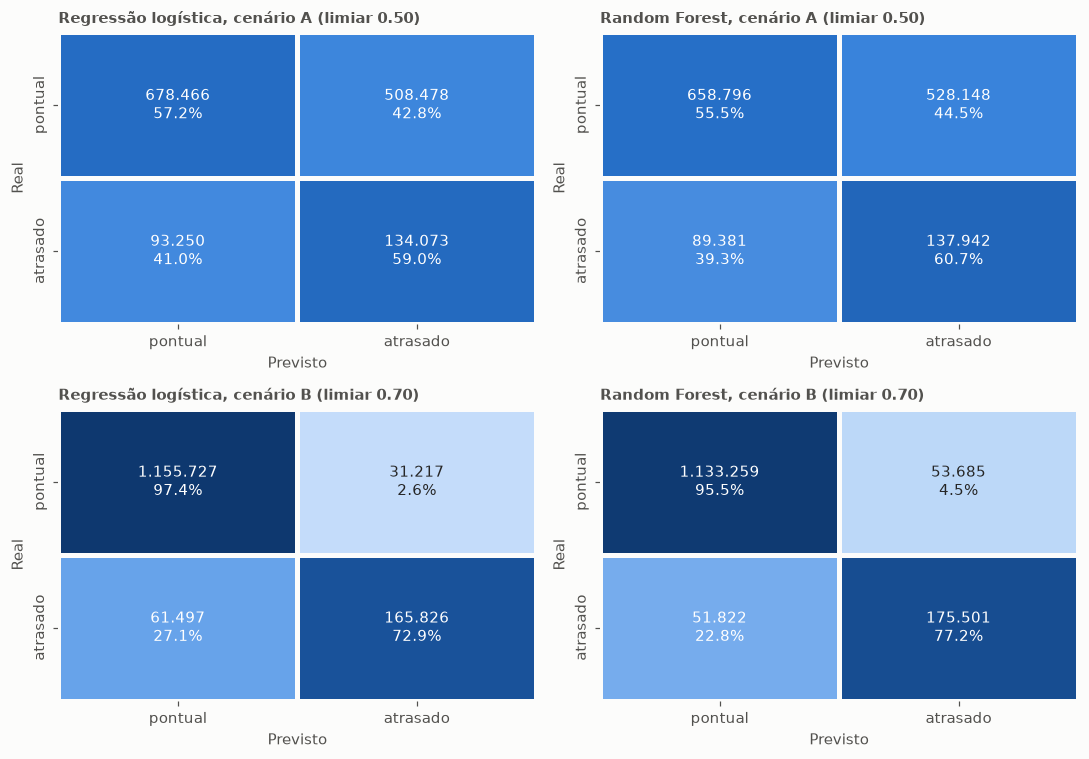

In [39]:
fig, eixos = plt.subplots(2, 2, figsize=(10, 7))
for ax, ((cenario, nome), pred) in zip(eixos.ravel(), predicoes.items()):
    m = avaliar_no_limiar(pred, tuning[(cenario, nome)]["limiar"])
    contagens = [[m["tn"], m["fp"]], [m["fn"], m["tp"]]]
    pct = [[c / sum(linha) for c in linha] for linha in contagens]
    anot = [[f"{contagens[i][j]:,}".replace(",", ".") + f"\n{100 * pct[i][j]:.1f}%" for j in range(2)] for i in range(2)]
    sns.heatmap(pct, annot=anot, fmt="", cmap=RAMPA_AZUL, vmin=0, vmax=1, cbar=False, ax=ax,
                linewidths=2, linecolor="#fcfcfb", xticklabels=["pontual", "atrasado"], yticklabels=["pontual", "atrasado"])
    ax.set_title(f"{nome}, cenário {cenario} (limiar {tuning[(cenario, nome)]['limiar']:.2f})", fontsize=10)
    ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.grid(False)
plt.tight_layout(); plt.show()

**Leitura das matrizes** (1.414.267 voos de teste, dos quais 227.323 atrasaram):
- **Cenário A, regressão logística:** pega 134.073 dos 227.323 atrasos (59%), mas gera 508.478 alarmes falsos: **45% de todos os voos recebem alerta**. Como alarme binário é pouco prático; serve melhor como **nota de risco** para ordenar voos.
- **Cenário B, regressão logística:** pega 165.826 atrasos (73%) com só 31.217 alarmes falsos (2,6% dos pontuais). O Random Forest pega mais atrasos (175.501, 77%), mas ao custo de mais alarmes falsos (53.685).
- **Escolha do limiar:** o limiar de F1 máximo (0,5 em A, 0,7 em B) é um compromisso. Numa aplicação real, o limiar deve refletir o custo de um alarme falso contra o de um atraso não detectado.

### 6.4 O que o modelo aprendeu
Importância dos atributos no Random Forest (queda média de impureza) e maiores coeficientes da regressão logística. Os nomes vêm dos metadados do vetor `features`.

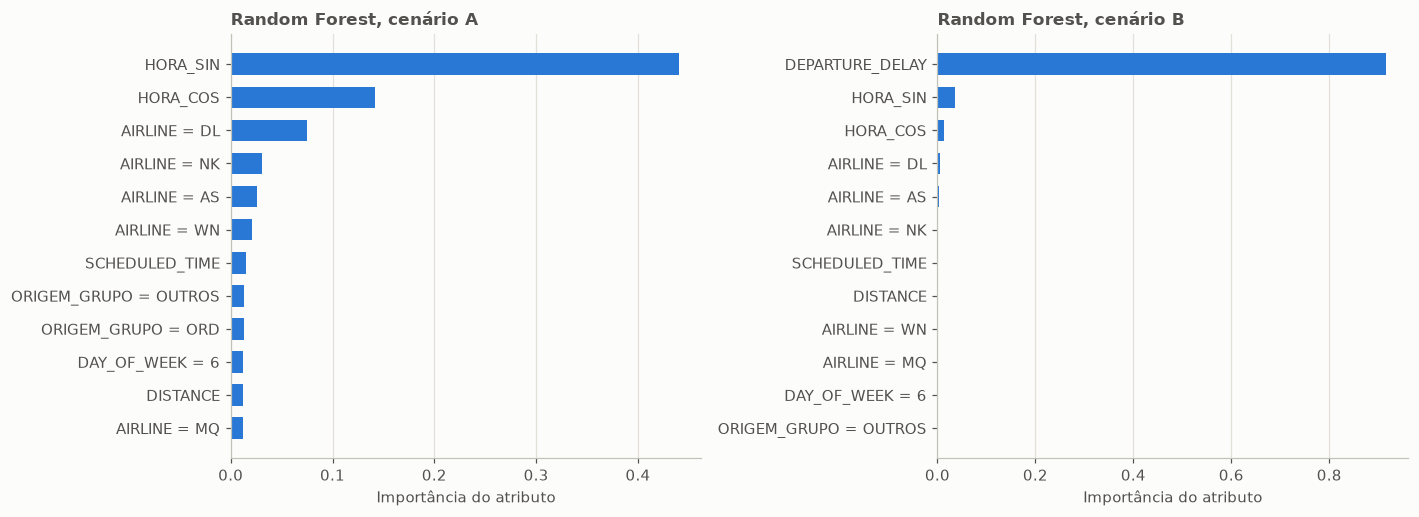

In [40]:
def nomes_dos_atributos(modelo, cenario):
    # Nomes vêm dos metadados do vetor 'features'; as numéricas padronizadas aparecem como num_padrao_<i>
    numericas = ["DISTANCE", "SCHEDULED_TIME", "HORA_SIN", "HORA_COS"] + (["DEPARTURE_DELAY"] if cenario == "B" else [])
    meta = modelo.transform(teste.limit(5)).schema["features"].metadata["ml_attr"]["attrs"]
    por_indice = {a["idx"]: a["name"] for lista in meta.values() for a in lista}
    nomes = [por_indice[i] for i in range(len(por_indice))]
    nomes = [numericas[int(n.rsplit("_", 1)[1])] if n.startswith("num_padrao_") else n for n in nomes]
    return [n.replace("_ohe_", " = ") for n in nomes]

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, cenario in zip(eixos, ("A", "B")):
    modelo = modelos_finais[(cenario, "Random Forest")]
    imp = pd.Series(modelo.stages[-1].featureImportances.toArray(), index=nomes_dos_atributos(modelo, cenario))
    topo = imp.sort_values().tail(12)
    ax.barh(topo.index, topo.values, color=AZUL, height=0.65)
    ax.grid(axis="y", visible=False); ax.grid(axis="x")
    ax.set_title(f"Random Forest, cenário {cenario}", fontsize=11)
    ax.set_xlabel("Importância do atributo")
plt.tight_layout(); plt.show()

In [41]:
for cenario in ("A", "B"):
    modelo = modelos_finais[(cenario, "Regressão logística")]
    coef = pd.Series(modelo.stages[-1].coefficients.toArray(), index=nomes_dos_atributos(modelo, cenario)).sort_values()
    print(f"--- Regressão logística, cenário {cenario}: coeficientes (positivo = aumenta a chance de atraso)")
    print("Maiores:", {k: round(v, 3) for k, v in coef.tail(5).iloc[::-1].items()})
    print("Menores:", {k: round(v, 3) for k, v in coef.head(5).items()})

--- Regressão logística, cenário A: coeficientes (positivo = aumenta a chance de atraso)
Maiores: {'AIRLINE = NK': 0.613, 'DESTINO_GRUPO = LGA': 0.486, 'AIRLINE = F9': 0.457, 'ORIGEM_GRUPO = LGA': 0.397, 'DESTINO_GRUPO = HNL': 0.303}
Menores: {'ORIGEM_GRUPO = SLC': -0.473, 'DESTINO_GRUPO = SLC': -0.465, 'HORA_SIN': -0.406, 'DESTINO_GRUPO = SNA': -0.392, 'AIRLINE = HA': -0.392}
--- Regressão logística, cenário B: coeficientes (positivo = aumenta a chance de atraso)
Maiores: {'DEPARTURE_DELAY': 4.646, 'AIRLINE = F9': 0.528, 'DESTINO_GRUPO = LGA': 0.492, 'DESTINO_GRUPO = HNL': 0.475, 'ORIGEM_GRUPO = LGA': 0.405}
Menores: {'AIRLINE = UA': -0.501, 'AIRLINE = WN': -0.467, 'DESTINO_GRUPO = SLC': -0.372, 'AIRLINE = DL': -0.367, 'DESTINO_GRUPO = PDX': -0.352}


**O que o modelo aprendeu:**
- **Cenário A:** no Random Forest, a hora programada (`HORA_SIN` e `HORA_COS`) concentra cerca de 58% da importância, seguida de companhia e aeroporto. Na regressão logística, `HORA_SIN` tem coeficiente negativo (horários mais tarde, com seno negativo, atrasam mais), o que confirma o efeito de acúmulo ao longo do dia visto na exploração. Companhias como Spirit (NK) e Frontier (F9) e aeroportos como LaGuardia (LGA) aumentam a chance de atraso; Salt Lake City (SLC) e Hawaiian (HA) reduzem.
- **Cenário B:** `DEPARTURE_DELAY` domina (~92% da importância no Random Forest; coeficiente padronizado de 4,6 na regressão logística, cerca de 9 vezes o do segundo atributo). Em outras palavras, **quem sai atrasado chega atrasado**.

### 6.5 Interpretação para a pergunta de negócio e limitações

**Resposta à pergunta de negócio.** Antes da decolagem, só com informação de planejamento, é possível **ordenar o risco** de atraso com um ganho moderado sobre o acaso (AUC 0,61), insuficiente para alarmes confiáveis. Já na saída do portão o problema se torna bem previsível (AUC 0,93, F1 0,78): útil para quem age *depois* da partida, por exemplo equipes no destino, conexões e portões. É importante ser honesto: parte desse ganho é quase tautológica, porque o atraso na saída é parte do atraso na chegada.

**Comparação com a referência.** Todos os modelos superam a linha de base (sempre pontual) em AUC, AUC-PR e F1; no cenário A a vantagem é pequena, no B é grande.

**Limitações**
- **Um único ano de dados** e um único corte treino/teste: não há intervalo de confiança, e a sazonalidade (inverno e verão piores) não pode ser aprendida (`MONTH` ficou fora).
- **Mudança de distribuição:** a taxa de atraso cai de 19,5% (treino) para 16,1% (teste), o que afeta F1 e precisão; os limiares foram escolhidos na validação.
- **Causas ausentes:** não há clima, restrições de tráfego aéreo nem a **rotação da aeronave** (o atraso do voo anterior do mesmo avião). Essas são as principais causas de atraso e explicam o teto do cenário A.
- **Probabilidades não calibradas:** os pesos de classe deslocam as probabilidades; `prob_atraso` serve para ordenar voos, não como probabilidade real.
- **Restrições do ambiente local:** o Random Forest final usou 50% do treino, o ajuste de hiperparâmetros foi feito em amostra de 10%, e a melhor configuração ficou na borda da grade; ele pode melhorar com mais profundidade e dados.
- **Viés de seleção:** cancelados e desviados (1,8%) foram removidos e não são aleatórios (mais frequentes no inverno e por clima), então o modelo descreve voos que operaram. Os IDs de aeroporto de outubro foram recuperados por um método heurístico (0,012% dos voos descartados).

## 7. Persistência do modelo

O `PipelineModel` completo (transformações + modelo) é salvo com `save()`. Como o `SQLTransformer` está dentro do Pipeline, o modelo carregado aceita as **colunas brutas** da base, sem nenhum pré-processamento externo. Salvamos também os limiares escolhidos na validação.

In [42]:
import json

DIR_MODELOS = Path("modelos")
DIR_MODELOS.mkdir(exist_ok=True)

def pasta_modelo(cenario, nome):
    return DIR_MODELOS / (cenario + "_" + ("rf" if "Forest" in nome else "lr"))

for (cenario, nome), modelo in modelos_finais.items():
    modelo.write().overwrite().save(str(pasta_modelo(cenario, nome)))     # PipelineModel.save()

with open(DIR_MODELOS / "limiares.json", "w") as arquivo:
    json.dump({c + "_" + ("rf" if "Forest" in n else "lr"): r["limiar"] for (c, n), r in tuning.items()}, arquivo, indent=1)
print("Modelos salvos em:", sorted(p.name for p in DIR_MODELOS.iterdir()))

Modelos salvos em: ['A_lr', 'A_rf', 'B_lr', 'B_rf', 'limiares.json']


**Prova de que o modelo salvo funciona:** recarregamos o melhor modelo do cenário A, aplicamos a voos do teste (colunas brutas) e conferimos que as probabilidades são **idênticas** às do modelo em memória.

In [43]:
from pyspark.ml import PipelineModel

modelo_carregado = PipelineModel.load(str(pasta_modelo("A", "Random Forest")))
amostra = teste.limit(2000)
p_memoria = com_prob(modelos_finais[("A", "Random Forest")].transform(amostra)).select("p1").toPandas()["p1"]
p_disco = com_prob(modelo_carregado.transform(amostra)).select("p1").toPandas()["p1"]
print("Máxima diferença entre as probabilidades (memória x disco):", float((p_memoria - p_disco).abs().max()))

limiar_a = tuning[("A", "Random Forest")]["limiar"]
(com_prob(modelo_carregado.transform(teste.limit(5)))
    .select("AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE", "ATRASADO",
            F.round("p1", 3).alias("prob_atraso"), (F.col("p1") >= limiar_a).cast("int").alias("alerta"))
    .show())

Máxima diferença entre as probabilidades (memória x disco): 0.0
+-------+--------------+-------------------+-------------------+--------+-----------+------+
|AIRLINE|ORIGIN_AIRPORT|DESTINATION_AIRPORT|SCHEDULED_DEPARTURE|ATRASADO|prob_atraso|alerta|
+-------+--------------+-------------------+-------------------+--------+-----------+------+
|     AA|           SEA|                DFW|                  5|       0|      0.458|     0|
|     DL|           SFO|                MSP|                  5|       0|      0.418|     0|
|     NK|           LAS|                MSP|                  5|       0|      0.604|     1|
|     AA|           LAX|                MIA|                 10|       0|      0.497|     0|
|     AA|           SFO|                CLT|                 10|       0|      0.491|     0|
+-------+--------------+-------------------+-------------------+--------+-----------+------+



## 8. Conclusão

**Resumo.** Construímos, com PySpark e Spark ML, um pipeline completo sobre 5,8 milhões de voos de 2015: ingestão com schema manual e Parquet, limpeza em Spark (incluindo a recuperação dos códigos IATA de outubro), engenharia de atributos e modelos dentro de um `Pipeline`, divisão temporal sem vazamento e persistência com `save()`.

| Cenário | Melhor modelo no teste | AUC-ROC | AUC-PR | F1 (atrasado) |
|---|---|---|---|---|
| Referência (sempre pontual) | | 0,500 | 0,161 | 0 |
| A, antes da decolagem | Random Forest | 0,612 | 0,221 | 0,309 |
| B, na saída do portão | Regressão logística | 0,928 | 0,852 | 0,782 |

**Lições principais**
1. **Vazamento é o maior risco:** usar as colunas de causa do atraso daria AUC 1,0 sem valor nenhum; a divisão temporal e o ajuste só no treino mantêm as métricas honestas.
2. **Informação de planejamento sozinha explica pouco do atraso** (AUC 0,61); o atraso na saída muda o jogo (AUC 0,93).
3. **O modelo mais complexo nem sempre vence:** a regressão logística superou o Random Forest no cenário B.

**Possíveis melhorias**
- **Rotação da aeronave:** usar `TAIL_NUMBER` para trazer o atraso de chegada do voo anterior do mesmo avião, informação disponível antes da próxima decolagem e provável maior ganho para o cenário A.
- **Dados externos:** clima (por exemplo NOAA) e congestionamento do aeroporto.
- **Mais histórico:** vários anos, com validação em janelas móveis, para capturar a sazonalidade e dar intervalos de confiança.
- **Modelos e escala:** Random Forest mais profundo e GBT com o treino completo em um cluster (o mesmo código roda sem mudanças, que é o argumento de dados massivos), além de calibração das probabilidades e escolha do limiar por custo.